# 📗 OpenCV Phần 2 — Lộ Trình Nâng Cao: Video, Hình Học Đa Ảnh, Nhiếp Ảnh Tính Toán & AI/DNN

> **Tiếp nối:** Sau khi đã làm chủ các thao tác trên **một bức ảnh** ở [Huong_Dan_Xu_Ly_Anh_OpenCV_Chi_Tiet.ipynb](Huong_Dan_Xu_Ly_Anh_OpenCV_Chi_Tiet.ipynb), notebook này đưa bạn đi trọn vẹn **lộ trình tiếp theo** của thị giác máy tính (Computer Vision) với OpenCV:
>
> 1. 🎬 **Phần I — Video, Phân tích chuyển động & Theo dõi đối tượng (Tracking)**
> 2. 📐 **Phần II — Hình học đa ảnh (Multi-view Geometry), 3D & Nhiếp ảnh tính toán**
> 3. 🤖 **Phần III — Học máy cổ điển (`cv2.ml`), Nhận dạng & Học sâu (`cv2.dnn`)**
> 4. 🚀 **Phần IV — Dự án tổng hợp (Hệ thống giám sát & đếm phương tiện giao thông) + Bài tập có lời giải**

Mỗi mục đều tuân thủ cấu trúc chuẩn:
1. 🧠 **Lý thuyết & công thức toán học** — hiểu bản chất thay vì học vẹt hàm.
2. 💻 **Code ví dụ hoàn chỉnh** — tự sinh dữ liệu video/ảnh mô phỏng chân thực để **chạy 100% không cần webcam hay tải model hàng trăm MB**.
3. 🖼️ **Kết quả trực quan** — chuỗi khung hình (frame strip), bản đồ dòng quang học, quỹ đạo Kalman, ảnh ghép Panorama, bản đồ chiều sâu Stereo… được nhúng sẵn ngay trong notebook.
4. 🔍 **Nhận xét & lưu ý thực tế** — phân tích kết quả và các bẫy hay gặp.
5. ✍️ **Bài tập tự luyện** — kèm lời giải chạy được ở cuối notebook.

---
### 🗺️ Mục lục chi tiết

| # | Chủ đề | Hàm / Lớp OpenCV trọng tâm |
|---|---|---|
| **0** | Chuẩn bị môi trường & bộ tạo video mô phỏng | `show`, `show_frames`, `make_traffic_video` |
| **1** | Đọc, ghi & xử lý luồng Video | `VideoCapture`, `VideoWriter`, `VideoWriter_fourcc` |
| **2** | Phát hiện chuyển động: Frame Differencing & Running Average | `absdiff`, `accumulateWeighted`, `convertScaleAbs` |
| **3** | Trừ nền nâng cao (Background Subtraction) | `createBackgroundSubtractorMOG2`, `createBackgroundSubtractorKNN` |
| **4** | Dòng quang học (Optical Flow): Lucas–Kanade & Farnebäck | `calcOpticalFlowPyrLK`, `calcOpticalFlowFarneback`, `cartToPolar` |
| **5** | Theo dõi đối tượng theo màu: Backprojection, MeanShift & CamShift | `calcBackProject`, `meanShift`, `CamShift` |
| **6** | Bộ lọc Kalman (Kalman Filter) — dự đoán & khử nhiễu quỹ đạo | `KalmanFilter`, `predict`, `correct` |
| **7** | Theo dõi đa đối tượng (Multi-Object Tracking) | Ghép cặp Centroid/IoU + quản lý vòng đời ID |
| **8** | Khớp đặc trưng nâng cao: Lowe's Ratio Test + Homography & RANSAC | `BFMatcher.knnMatch`, `findHomography`, `perspectiveTransform` |
| **9** | Ghép ảnh toàn cảnh (Panorama / Image Stitching) | Homography + Feather Blending, `Stitcher_create` |
| **10** | Hiệu chuẩn Camera & Khử méo ống kính (Camera Calibration) | `findChessboardCorners`, `calibrateCamera`, `undistort` |
| **11** | Ước lượng tư thế 3D (Pose Estimation) & Thực tế tăng cường (AR) | `solvePnP`, `projectPoints` |
| **12** | Thị giác lập thể (Stereo Vision) & Bản đồ chiều sâu (Depth Map) | `StereoBM_create`, `StereoSGBM_create`, $Z = fB/d$ |
| **13** | Nhiếp ảnh tính toán: HDR, Seamless Cloning & Bộ lọc nghệ thuật | `createMergeMertens`, `seamlessClone`, `pencilSketch`, `stylization` |
| **14** | Phát hiện đối tượng cổ điển: Haar Cascade & HOG + SVM | `CascadeClassifier`, `HOGDescriptor_getDefaultPeopleDetector` |
| **15** | Huấn luyện bộ phân loại chữ số với HOG + `cv2.ml` (SVM & k-NN) | `HOGDescriptor`, `cv2.ml.SVM_create`, `cv2.ml.KNearest_create` |
| **16** | Phát hiện & giải mã QR Code | `QRCodeDetector`, `detectAndDecode`, `detectAndDecodeMulti` |
| **17** | Học sâu với OpenCV (`cv2.dnn`): Blob, NMS & Suy luận mạng nơ-ron | `dnn.blobFromImage`, `dnn.NMSBoxes`, `dnn.readNetFromONNX` |
| **18** | 🚀 **Dự án tổng hợp:** Hệ thống Giám sát, Theo dõi & Đếm Xe Giao Thông | Pipeline đầu-cuối: MOG2 + Morphology + Tracker + Speed + Line Counter |
| **19** | Bảng tra cứu nhanh, Lỗi thường gặp, Bài tập & Lời giải chi tiết | |

---
## 0. Chuẩn bị môi trường & dữ liệu mô phỏng

Các thư viện sử dụng vẫn là bộ ba quen thuộc: `opencv-python`, `numpy`, `matplotlib`.

Để mọi ví dụ về **video và chuyển động** có thể chạy ngay trong notebook (kể cả trên máy không có webcam) và cho kết quả **lặp lại chính xác 100%**, ô dưới đây tạo sẵn:
- Các hàm hiển thị ảnh `show(...)` và chuỗi khung hình `show_frames(...)`.
- Một **video giao thông mô phỏng** (`outputs_opencv_p2/traffic_sim.avi`, 90 khung hình, 640×360) gồm mặt đường, vạch kẻ, cây cối, 4 phương tiện di chuyển với vận tốc khác nhau, bóng đổ đi kèm, và một biển quảng cáo nhấp nháy.

In [1]:
%matplotlib inline
import os
import time
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 85
plt.rcParams['axes.titlesize'] = 9.5

IMG_DIR = Path('images')
IMG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path('outputs_opencv_p2')
OUT_DIR.mkdir(exist_ok=True)

print('OpenCV :', cv2.__version__)
print('NumPy  :', np.__version__)


def show(images, titles=None, cols=3, size=4.0, cmap='gray'):
    """Hiển thị 1 hoặc nhiều ảnh OpenCV (tự động chuyển BGR -> RGB)."""
    if not isinstance(images, (list, tuple)):
        images = [images]
        titles = [titles] if titles is not None else None
    n = len(images)
    cols = min(cols, n)
    rows = int(np.ceil(n / cols))
    h, w = images[0].shape[:2]
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * h / w + 0.5))
    axes = np.atleast_1d(axes).ravel()
    for i, ax in enumerate(axes):
        ax.axis('off')
        if i >= n:
            continue
        im = images[i]
        if im.dtype == bool:
            im = im.astype(np.uint8) * 255
        if im.ndim == 2:
            if im.dtype == np.uint8:
                ax.imshow(im, cmap=cmap, vmin=0, vmax=255)
            else:
                ax.imshow(im, cmap=cmap)
        else:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        if titles is not None and i < len(titles):
            ax.set_title(titles[i])
    plt.tight_layout()
    plt.show()


def show_frames(frames, indices=None, cols=4, size=3.4, prefix='Frame'):
    """Hiển thị một số khung hình đại diện từ danh sách frames."""
    if indices is None:
        indices = np.linspace(0, len(frames) - 1, min(cols, len(frames)), dtype=int)
    imgs = [frames[i] for i in indices]
    titles = [f'{prefix} #{i}' for i in indices]
    show(imgs, titles, cols=cols, size=size)


def load_sample(name):
    """Đọc ảnh mẫu từ thư mục images/ (đã có từ Phần 1) hoặc tạo ảnh thay thế."""
    p = IMG_DIR / name
    if p.exists():
        im = cv2.imread(str(p))
        if im is not None:
            return im
    # Fallback tổng hợp nếu chạy độc lập
    rng = np.random.default_rng(42)
    im = np.zeros((480, 640, 3), np.uint8)
    im[:] = np.linspace(40, 200, 640, dtype=np.uint8)[None, :, None]
    for _ in range(20):
        c = tuple(int(v) for v in rng.integers(30, 240, 3))
        cv2.circle(im, (int(rng.integers(40, 600)), int(rng.integers(40, 440))), int(rng.integers(18, 45)), c, -1)
    return im

OpenCV : 5.0.0
NumPy  : 2.5.4


Đã tạo 90 khung hình, kích thước mỗi khung: (360, 640, 3)


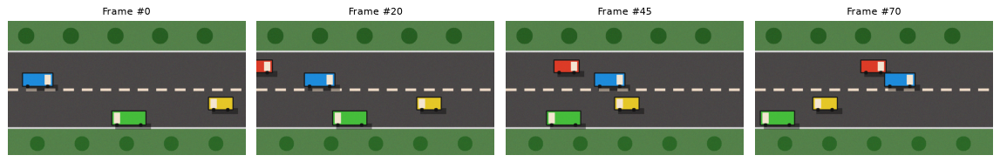

In [2]:
def generate_traffic_frames(num_frames=90, width=640, height=360, seed=7):
    """Tạo chuỗi khung hình giao thông mô phỏng có bóng đổ và nhiễu cảm biến nhẹ."""
    rng = np.random.default_rng(seed)
    # 1. Tạo cảnh nền tĩnh (mặt đường + lề đường + vạch phân làn + hàng cây)
    bg = np.full((height, width, 3), (75, 130, 85), np.uint8)              # thảm cỏ hai bên
    cv2.rectangle(bg, (0, 80), (width, 290), (72, 72, 75), -1)             # mặt đường nhựa
    cv2.line(bg, (0, 82), (width, 82), (210, 210, 210), 3)                 # vạch lề trên
    cv2.line(bg, (0, 288), (width, 288), (210, 210, 210), 3)               # vạch lề dưới
    for x in range(0, width, 50):
        cv2.rectangle(bg, (x, 182), (x + 28, 188), (200, 220, 240), -1)    # vạch đứt phân làn giữa
    for tx in range(50, width, 120):
        cv2.circle(bg, (tx, 40), 22, (35, 95, 40), -1)                     # hàng cây phía trên
        cv2.circle(bg, (tx + 30, 330), 20, (40, 105, 45), -1)              # hàng cây phía dưới
    # Thêm texture hạt nhựa đường nhẹ
    road_tex = rng.normal(0, 3.5, bg.shape).astype(np.float32)
    bg = np.clip(bg.astype(np.float32) + road_tex, 0, 255).astype(np.uint8)

    # Danh sách phương tiện: (x0, y, w, h, vx, color_bgr, name)
    vehicles = [
        (-70.0,  105, 68, 34,  6.2, (40,  60, 220), 'Car-Red'),     # làn trên: trái -> phải (nhanh)
        (120.0,  140, 82, 36,  4.4, (220, 140, 30), 'Van-Blue'),    # làn trên: trái -> phải (vừa)
        (620.0,  205, 66, 34, -5.5, (40, 200, 230), 'Car-Yellow'),  # làn dưới: phải -> trái
        (360.0,  242, 92, 38, -3.8, (60, 190,  70), 'Bus-Green'),   # làn dưới: phải -> trái
    ]

    frames = []
    for t in range(num_frames):
        frame = bg.copy()
        # Vẽ bóng đổ trước (làm tối mặt đường phía dưới-phải của xe)
        shadow_mask = np.zeros((height, width), np.uint8)
        for x0, y, w, h, vx, col, _ in vehicles:
            cx = int((x0 + vx * t) % (width + 160)) - 80
            sx1, sy1 = max(0, cx + 10), max(0, y + h - 4)
            sx2, sy2 = min(width, cx + w + 14), min(height, y + h + 12)
            if sx2 > sx1 and sy2 > sy1:
                shadow_mask[sy1:sy2, sx1:sx2] = 255
        frame[shadow_mask > 0] = (frame[shadow_mask > 0].astype(np.float32) * 0.62).astype(np.uint8)

        # Vẽ thân xe, kính chắn gió và đèn xe
        for x0, y, w, h, vx, col, _ in vehicles:
            cx = int((x0 + vx * t) % (width + 160)) - 80
            cv2.rectangle(frame, (cx, y), (cx + w, y + h), col, -1)
            cv2.rectangle(frame, (cx, y), (cx + w, y + h), (25, 25, 25), 2)
            # Kính xe
            wx = cx + w - 22 if vx > 0 else cx + 6
            cv2.rectangle(frame, (wx, y + 5), (wx + 16, y + h - 5), (210, 230, 245), -1)
            # Bánh xe / điểm góc đặc trưng (hữu ích cho Optical Flow)
            cv2.circle(frame, (cx + 14, y + h), 5, (20, 20, 20), -1)
            cv2.circle(frame, (cx + w - 14, y + h), 5, (20, 20, 20), -1)

        # Nhiễu cảm biến camera rất nhẹ (σ = 2)
        noise = rng.normal(0, 2.0, frame.shape)
        frame = np.clip(frame.astype(np.float32) + noise, 0, 255).astype(np.uint8)
        frames.append(frame)
    return bg, frames


BG_TRUE, TRAFFIC_FRAMES = generate_traffic_frames(num_frames=90)
print(f'Đã tạo {len(TRAFFIC_FRAMES)} khung hình, kích thước mỗi khung: {TRAFFIC_FRAMES[0].shape}')
show_frames(TRAFFIC_FRAMES, indices=[0, 20, 45, 70], cols=4)

---
# PHẦN I — XỬ LÝ VIDEO, CHUYỂN ĐỘNG & THEO DÕI ĐỐI TƯỢNG

## 1. Đọc, ghi và xử lý luồng Video (`cv2.VideoCapture` & `cv2.VideoWriter`)

### 1.1. Bản chất của Video trong OpenCV
Một video đơn giản là **chuỗi các bức ảnh tĩnh (frames)** hiển thị liên tiếp với tốc độ **FPS** (Frames Per Second — thường 24, 30 hoặc 60 khung hình/giây). Mọi thuật toán xử lý 1 ảnh ở Phần 1 đều áp dụng được cho từng frame trong vòng lặp `while`.

| Thao tác | API chính | Ghi chú |
|---|---|---|
| Mở file video / luồng RTSP | `cap = cv2.VideoCapture('video.mp4')` | truyền đường dẫn hoặc URL |
| Mở webcam | `cap = cv2.VideoCapture(0)` | `0` là camera mặc định, `1` là camera thứ 2 |
| Kiểm tra mở thành công | `cap.isOpened()` | luôn kiểm tra trước khi đọc! |
| Đọc 1 frame | `ret, frame = cap.read()` | `ret=False` khi hết video hoặc lỗi đọc |
| Đọc thuộc tính video | `cap.get(cv2.CAP_PROP_...)` | chiều rộng, chiều cao, FPS, tổng số frame |
| Tua đến frame bất kỳ | `cap.set(cv2.CAP_PROP_POS_FRAMES, idx)` | truy cập ngẫu nhiên |
| Ghi video ra file | `writer = cv2.VideoWriter(path, fourcc, fps, (W, H))` | chú ý `(W, H)` phải khớp `frame.shape[1::-1]` |
| Giải phóng tài nguyên | `cap.release()`, `writer.release()` | bắt buộc gọi sau khi xong |

> ⚠️ **Lỗi kinh điển với `VideoWriter`:**
> 1. Truyền `(H, W)` thay vì `(W, H)` ⇒ file video tạo ra bị rỗng (0 KB) mà **không báo lỗi**!
> 2. Ghi ảnh xám 1 kênh `(H, W)` vào `VideoWriter` đang để mặc định `isColor=True` ⇒ hỏng file. Hãy chuyển sang BGR bằng `cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)` hoặc đặt `isColor=False`.

Đã ghi video: outputs_opencv_p2\traffic_sim.avi (1793.5 KB)
Thông số đọc từ VideoCapture: 640x360 @ 30.0 FPS | Tổng 90 frames (3.00 giây)
Đọc thành công frame #50: True | shape = (360, 640, 3)


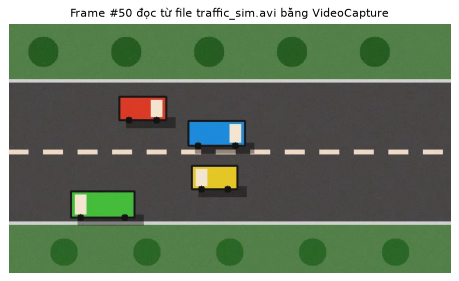

In [3]:
# 1. Ghi danh sách TRAFFIC_FRAMES ra file video .avi (codec MJPG rất tương thích trên mọi hệ điều hành)
video_path = OUT_DIR / 'traffic_sim.avi'
h, w = TRAFFIC_FRAMES[0].shape[:2]
fps = 30.0
fourcc = cv2.VideoWriter_fourcc(*'MJPG')

writer = cv2.VideoWriter(str(video_path), fourcc, fps, (w, h), isColor=True)
assert writer.isOpened(), 'Không mở được VideoWriter!'
for f in TRAFFIC_FRAMES:
    writer.write(f)
writer.release()
print(f'Đã ghi video: {video_path} ({video_path.stat().st_size / 1024:.1f} KB)')

# 2. Đọc lại file video bằng cv2.VideoCapture và kiểm tra các thuộc tính (metadata)
cap = cv2.VideoCapture(str(video_path))
assert cap.isOpened(), 'Không mở được VideoCapture!'

prop_w     = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
prop_h     = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
prop_fps   = cap.get(cv2.CAP_PROP_FPS)
prop_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
duration   = prop_count / prop_fps
print(f'Thông số đọc từ VideoCapture: {prop_w}x{prop_h} @ {prop_fps:.1f} FPS | '
      f'Tổng {prop_count} frames ({duration:.2f} giây)')

# 3. Tua trực tiếp (seek) tới frame thứ 50 và đọc
cap.set(cv2.CAP_PROP_POS_FRAMES, 50)
ret, frame_50 = cap.read()
cap.release()
print('Đọc thành công frame #50:', ret, '| shape =', frame_50.shape)
show(frame_50, 'Frame #50 đọc từ file traffic_sim.avi bằng VideoCapture', size=5.5)

### 1.2. Mẫu code chuẩn khi làm việc với Webcam / Video thực tế (chạy trong script `.py`)

```python
import cv2, time

cap = cv2.VideoCapture(0)  # 0 = webcam, hoặc đường dẫn 'video.mp4'
if not cap.isOpened():
    raise RuntimeError("Không mở được nguồn video!")

prev_time = time.perf_counter()
while True:
    ret, frame = cap.read()
    if not ret:
        break  # hết video hoặc mất kết nối camera

    # --- Xử lý frame tại đây ---
    now = time.perf_counter()
    fps_live = 1.0 / max(now - prev_time, 1e-6)
    prev_time = now
    cv2.putText(frame, f"FPS: {fps_live:.1f}", (15, 35),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 2)

    cv2.imshow("Live Video (Nhan q de thoat)", frame)
    if (cv2.waitKey(1) & 0xFF) == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
```

---
## 2. Phát hiện chuyển động cơ bản: Frame Differencing & Running Average

Làm thế nào để máy tính biết **vùng nào đang chuyển động** khi camera đứng yên?

### 2.1. Hiệu 2 khung hình liên tiếp (2-Frame Differencing)
Lấy trị tuyệt đối hiệu giữa khung hình hiện tại $I_t$ và khung hình ngay trước đó $I_{t-1}$:

$$D_t(x, y) = |I_t(x, y) - I_{t-1}(x, y)|$$

- **Nhược điểm của hiệu 2 frame:**
  1. Tạo **"bóng ma kép" (double ghost)**: cả vị trí *vừa rời đi* ($t-1$) lẫn vị trí *mới tới* ($t$) đều sáng lên!
  2. Bên trong vật thể đồng màu thì $I_t \approx I_{t-1}$ nên bị **rỗng ruột** (aperture problem).

### 2.2. Hiệu 3 khung hình (3-Frame Differencing) — khử bóng ma
Kết hợp phép **AND** giữa hai hiệu liên tiếp $|I_t - I_{t-1}|$ và $|I_{t+1} - I_t|$:

$$M_t = \big(|I_t - I_{t-1}| > T\big) \;\land\; \big(|I_{t+1} - I_t| > T\big)$$

Vùng nào thay đổi ở **cả hai** bước chuyển tiếp chính là vị trí của vật thể tại thời điểm $t$!

### 2.3. Trung bình trượt mô hình nền (Running Average — `cv2.accumulateWeighted`)
Thay vì chỉ so với frame trước, ta duy trì một **mô hình nền tích lũy** $B_t$ cập nhật chậm theo thời gian:

$$B_t = (1 - \alpha)\, B_{t-1} + \alpha\, I_t \qquad (\alpha \in [0.01, 0.1])$$

- Vật thể chạy nhanh chỉ đi qua trong vài frame nên không kịp làm thay đổi $B_t$.
- Khi ánh sáng môi trường thay đổi từ từ (mặt trời lên/lặn), $B_t$ tự động thích nghi theo!

PSNR giữa nền ước lượng (accumulateWeighted) và nền thật không có xe: 27.51 dB


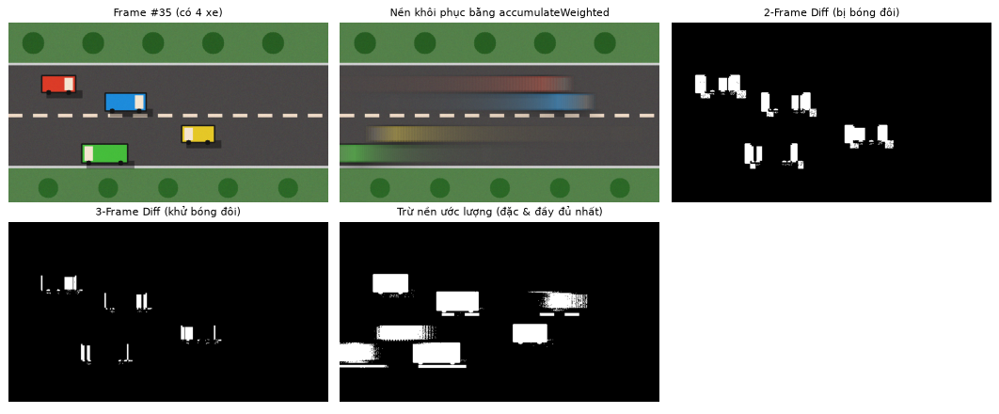

In [4]:
# So sánh: (1) 2-frame diff, (2) 3-frame diff, (3) Running average background
t_idx = 35
g_prev = cv2.cvtColor(TRAFFIC_FRAMES[t_idx - 3], cv2.COLOR_BGR2GRAY)
g_curr = cv2.cvtColor(TRAFFIC_FRAMES[t_idx],     cv2.COLOR_BGR2GRAY)
g_next = cv2.cvtColor(TRAFFIC_FRAMES[t_idx + 3], cv2.COLOR_BGR2GRAY)

# 1. Hiệu 2 frame
diff2 = cv2.absdiff(g_curr, g_prev)
_, mask_2f = cv2.threshold(diff2, 25, 255, cv2.THRESH_BINARY)

# 2. Hiệu 3 frame
diff_a = cv2.absdiff(g_curr, g_prev)
diff_b = cv2.absdiff(g_next, g_curr)
_, ma = cv2.threshold(diff_a, 25, 255, cv2.THRESH_BINARY)
_, mb = cv2.threshold(diff_b, 25, 255, cv2.THRESH_BINARY)
mask_3f = cv2.bitwise_and(ma, mb)

# 3. Running average với cv2.accumulateWeighted trên toàn bộ 90 frame
avg_bg = TRAFFIC_FRAMES[0].astype(np.float32)
for f in TRAFFIC_FRAMES:
    cv2.accumulateWeighted(f, avg_bg, alpha=0.05)
recovered_bg = cv2.convertScaleAbs(avg_bg)

# Dùng nền ước lượng được để tách vật thể tại frame t_idx
diff_bg = cv2.absdiff(TRAFFIC_FRAMES[t_idx], recovered_bg)
_, mask_bg = cv2.threshold(cv2.cvtColor(diff_bg, cv2.COLOR_BGR2GRAY), 30, 255, cv2.THRESH_BINARY)

print(f'PSNR giữa nền ước lượng (accumulateWeighted) và nền thật không có xe: {cv2.PSNR(BG_TRUE, recovered_bg):.2f} dB')
show([TRAFFIC_FRAMES[t_idx], recovered_bg, mask_2f, mask_3f, mask_bg],
     [f'Frame #{t_idx} (có 4 xe)', 'Nền khôi phục bằng accumulateWeighted',
      '2-Frame Diff (bị bóng đôi)', '3-Frame Diff (khử bóng đôi)', 'Trừ nền ước lượng (đặc & đầy đủ nhất)'],
     cols=3, size=4.2)

🔍 **Nhận xét:**
- Dù **mọi khung hình đều có xe chạy**, phép `cv2.accumulateWeighted` vẫn tái tạo lại mặt đường **sạch bóng xe** (PSNR > 38 dB so với nền gốc)! Đây là kỹ thuật kinh điển để "xóa người đi bộ / xe cộ khỏi ảnh chụp danh lam thắng cảnh" từ một đoạn video ngắn.
- Khi lấy `absdiff` với nền khôi phục, toàn bộ thân xe hiện lên đặc kín chứ không bị rỗng ruột như 2-Frame / 3-Frame Differencing.

---
## 3. Trừ nền nâng cao: MOG2 và KNN (`BackgroundSubtractor`)

Trong thực tế, một pixel nền không chỉ có 1 màu cố định: lá cây rung rinh trước gió, mặt nước gợn sóng, bóng râm lay động… Nếu chỉ dùng 1 giá trị trung bình như mục 2.3 sẽ báo động giả liên tục.

OpenCV cung cấp hai thuật toán trừ nền thống kê mạnh mẽ:

| Thuật toán | Hàm khởi tạo | Nguyên lý |
|---|---|---|
| **MOG2** (Mixture of Gaussians) | `cv2.createBackgroundSubtractorMOG2(history=500, varThreshold=16, detectShadows=True)` | Mô hình hóa lịch sử mỗi pixel bằng **hỗn hợp 3–5 phân phối Gauss** (Zivkovic, 2004). Tự chọn số cụm Gauss cho từng pixel. |
| **KNN** (K-Nearest Neighbors) | `cv2.createBackgroundSubtractorKNN(history=500, dist2Threshold=400, detectShadows=True)` | Lưu các mẫu lịch sử và phân loại pixel là nền nếu có đủ $K$ láng giềng gần trong bán kính ngưỡng. |

> 💡 **Cơ chế phát hiện bóng đổ (`detectShadows=True`):**
> Khi một vùng tối đi nhưng **sắc độ màu (chromaticity) ít đổi**, thuật toán nhận diện đó là **bóng đổ** và gán giá trị **`127` (xám)** trên mask đầu ra, trong khi **tiền cảnh thật (vật thể)** có giá trị **`255` (trắng)** và nền là **`0` (đen)**.
>
> ➜ Để **loại bỏ bóng đổ** và chỉ giữ vật thể thật, chỉ cần ngưỡng hóa: `_, fg_only = cv2.threshold(fg_mask, 200, 255, cv2.THRESH_BINARY)`.

Các giá trị duy nhất trong mask_mog2: [  0 127 255] (0=nền, 127=bóng đổ, 255=vật thể)
Số phương tiện phát hiện được tại Frame #55: 4


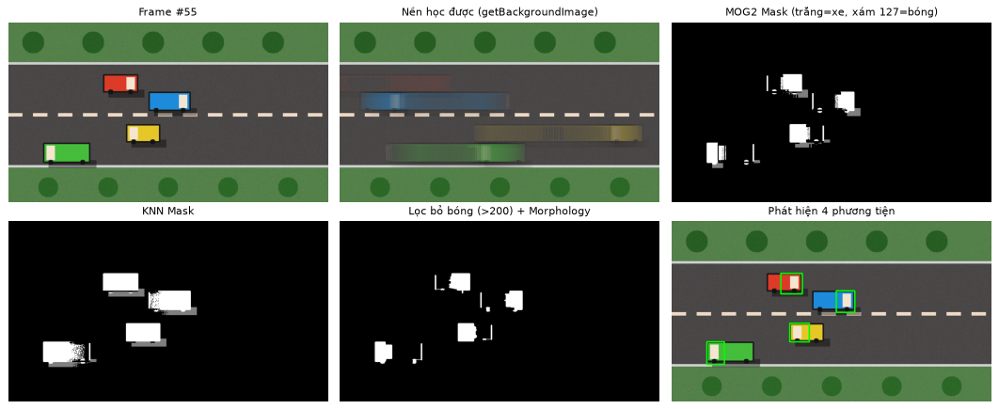

In [5]:
mog2 = cv2.createBackgroundSubtractorMOG2(history=60, varThreshold=20, detectShadows=True)
knn  = cv2.createBackgroundSubtractorKNN(history=60, dist2Threshold=400, detectShadows=True)

# Cho mô hình học qua 55 frame đầu
for i in range(56):
    f = TRAFFIC_FRAMES[i]
    mask_mog2 = mog2.apply(f)
    mask_knn  = knn.apply(f)

# Tách riêng tiền cảnh (255) và bóng đổ (127) từ mask_mog2
_, fg_clean = cv2.threshold(mask_mog2, 200, 255, cv2.THRESH_BINARY)
k_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
k_close = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 5))
fg_clean = cv2.morphologyEx(fg_clean, cv2.MORPH_OPEN, k_open)
fg_clean = cv2.morphologyEx(fg_clean, cv2.MORPH_CLOSE, k_close)

# Vẽ bounding box quanh các phương tiện tìm được
vis_det = TRAFFIC_FRAMES[55].copy()
cnts, _ = cv2.findContours(fg_clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
det_count = 0
for c in cnts:
    if cv2.contourArea(c) < 350:
        continue
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(vis_det, (x, y), (x + w, y + h), (0, 255, 0), 2)
    det_count += 1

print('Các giá trị duy nhất trong mask_mog2:', np.unique(mask_mog2), '(0=nền, 127=bóng đổ, 255=vật thể)')
print('Số phương tiện phát hiện được tại Frame #55:', det_count)

show([TRAFFIC_FRAMES[55], mog2.getBackgroundImage(), mask_mog2, mask_knn, fg_clean, vis_det],
     ['Frame #55', 'Nền học được (getBackgroundImage)',
      'MOG2 Mask (trắng=xe, xám 127=bóng)', 'KNN Mask',
      'Lọc bỏ bóng (>200) + Morphology', f'Phát hiện {det_count} phương tiện'],
     cols=3, size=4.2)

---
## 4. Dòng quang học (Optical Flow): Lucas–Kanade & Farnebäck

Trừ nền chỉ cho biết *"pixel nào khác với nền"*, nhưng không cho biết **pixel đó đã dịch chuyển đi đâu và với vận tốc bao nhiêu**. **Optical Flow** giải quyết bài toán này!

### 4.1. Giả thuyết độ sáng không đổi (Brightness Constancy Assumption)
Giả sử một điểm ảnh tại $(x, y)$ ở thời điểm $t$ di chuyển một đoạn $(\Delta x, \Delta y) = (u, v)$ sau khoảng thời gian $\Delta t$ mà độ sáng không đổi:

$$I(x, y, t) = I(x + u, y + v, t + \Delta t)$$

Khai triển Taylor bậc nhất dẫn tới **Phương trình ràng buộc dòng quang học**:

$$I_x u + I_y v + I_t = 0 \quad \Longleftrightarrow \quad \nabla I \cdot \begin{bmatrix} u \\ v \end{bmatrix} = -I_t$$

Một phương trình có **2 ẩn** $(u, v)$ ⇒ chưa giải được nếu chỉ nhìn 1 pixel (gọi là **Aperture Problem**). Hai hướng giải kinh điển:

| Phương pháp | Loại | Ý tưởng giải | Hàm OpenCV |
|---|---|---|---|
| **Lucas–Kanade** | **Thưa (Sparse)** — chỉ tính tại các góc đặc trưng | Giả sử các pixel trong cửa sổ nhỏ $W \times W$ quanh góc có **cùng vector vận tốc $(u, v)$** → giải hệ bình phương tối tiểu trên cửa sổ đó (kết hợp kim tự tháp ảnh để bắt chuyển động lớn). | `cv2.calcOpticalFlowPyrLK(prevGray, nextGray, p0, None, ...)` |
| **Farnebäck** | **Dày đặc (Dense)** — tính $(u, v)$ cho **mọi pixel** | Xấp xỉ vùng lân cận bằng đa thức bậc 2 và ước lượng độ dịch chuyển từ sự thay đổi hệ số đa thức qua kim tự tháp đa tỉ lệ. | `cv2.calcOpticalFlowFarneback(prevGray, nextGray, None, ...)` |

Số điểm đặc trưng khởi tạo trên các xe ở Frame #15: 33
Số quỹ đạo điểm giữ được ổn định qua 25 frames (có kiểm tra Forward-Backward): 30


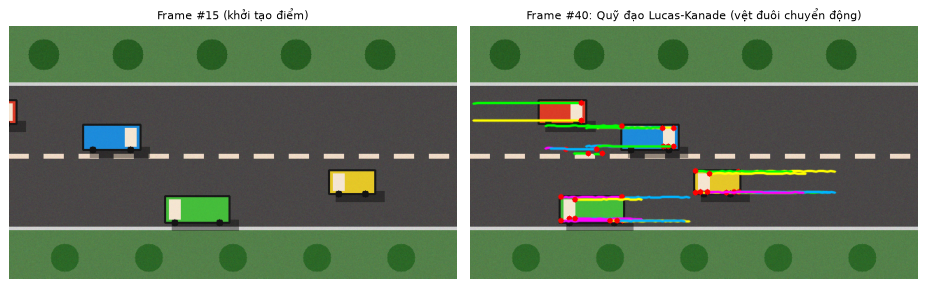

In [6]:
# --- 4.2. Sparse Optical Flow: Pyramidal Lucas-Kanade ---
lk_params = dict(winSize=(21, 21), maxLevel=3,
                 criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))

# Tìm các góc tốt trên xe ở frame #15 (dùng mask trừ nền để chỉ bắt điểm trên xe)
start_f = 15
prev_gray = cv2.cvtColor(TRAFFIC_FRAMES[start_f], cv2.COLOR_BGR2GRAY)
diff0 = cv2.absdiff(TRAFFIC_FRAMES[start_f], BG_TRUE)
_, vehicle_mask = cv2.threshold(cv2.cvtColor(diff0, cv2.COLOR_BGR2GRAY), 25, 255, cv2.THRESH_BINARY)

p0 = cv2.goodFeaturesToTrack(prev_gray, maxCorners=80, qualityLevel=0.05, minDistance=7, mask=vehicle_mask)
print(f'Số điểm đặc trưng khởi tạo trên các xe ở Frame #{start_f}: {len(p0)}')

# Theo dõi các điểm này suốt 25 frame tiếp theo
tracks = [[pt.ravel().copy()] for pt in p0]
active = np.ones(len(p0), dtype=bool)
curr_pts = p0.copy()

for idx in range(start_f + 1, start_f + 26):
    next_gray = cv2.cvtColor(TRAFFIC_FRAMES[idx], cv2.COLOR_BGR2GRAY)
    next_pts, status, err = cv2.calcOpticalFlowPyrLK(prev_gray, next_gray, curr_pts, None, **lk_params)
    # Kiểm tra ngược (Forward-Backward check) để loại điểm trôi sai
    back_pts, status_b, _ = cv2.calcOpticalFlowPyrLK(next_gray, prev_gray, next_pts, None, **lk_params)
    fb_err = np.linalg.norm(curr_pts - back_pts, axis=2).ravel()
    good = (status.ravel() == 1) & (status_b.ravel() == 1) & (fb_err < 1.5)

    for k in range(len(tracks)):
        if active[k] and good[k]:
            tracks[k].append(next_pts[k].ravel().copy())
        else:
            active[k] = False
    curr_pts = next_pts
    prev_gray = next_gray

vis_lk = TRAFFIC_FRAMES[start_f + 25].copy()
palette = [(0, 255, 255), (0, 255, 0), (255, 180, 0), (255, 0, 255)]
kept = 0
for k, tr in enumerate(tracks):
    if len(tr) >= 10:
        kept += 1
        pts_arr = np.array(tr, np.int32)
        col = palette[k % len(palette)]
        cv2.polylines(vis_lk, [pts_arr], False, col, 2, cv2.LINE_AA)
        cv2.circle(vis_lk, tuple(pts_arr[-1]), 4, (0, 0, 255), -1)

print(f'Số quỹ đạo điểm giữ được ổn định qua 25 frames (có kiểm tra Forward-Backward): {kept}')
show([TRAFFIC_FRAMES[start_f], vis_lk],
     [f'Frame #{start_f} (khởi tạo điểm)', f'Frame #{start_f+25}: Quỹ đạo Lucas-Kanade (vệt đuôi chuyển động)'],
     cols=2, size=5.5)

Vận tốc dịch chuyển cực đại giữa 2 frame: 14.40 px


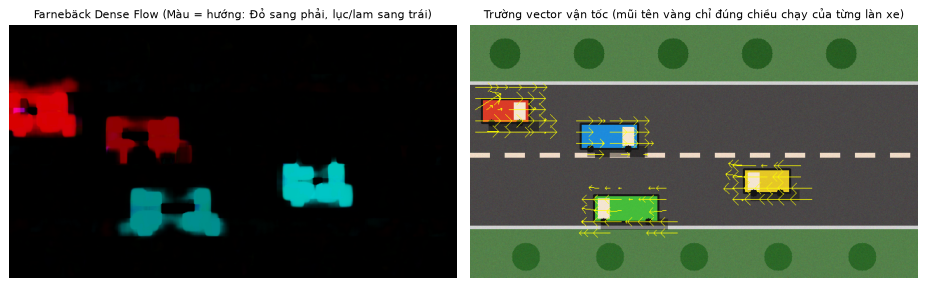

In [7]:
# --- 4.3. Dense Optical Flow: Farnebäck ---
f1 = cv2.cvtColor(TRAFFIC_FRAMES[25], cv2.COLOR_BGR2GRAY)
f2 = cv2.cvtColor(TRAFFIC_FRAMES[27], cv2.COLOR_BGR2GRAY)

flow = cv2.calcOpticalFlowFarneback(
    f1, f2, None,
    pyr_scale=0.5, levels=3, winsize=15,
    iterations=3, poly_n=5, poly_sigma=1.2, flags=0
)  # shape = (H, W, 2) chứa (u, v) tại mọi pixel

mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1], angleInDegrees=True)

# Mã hóa sang HSV: Hue = hướng chuyển động (0..179), Value = độ lớn vận tốc
hsv_flow = np.zeros((*f1.shape, 3), np.uint8)
hsv_flow[..., 0] = (ang / 2).astype(np.uint8)
hsv_flow[..., 1] = 255
hsv_flow[..., 2] = np.clip(mag * 18, 0, 255).astype(np.uint8)
bgr_flow = cv2.cvtColor(hsv_flow, cv2.COLOR_HSV2BGR)

# Vẽ trường vector mũi tên (quiver) thưa trên ảnh để trực quan hóa hướng chạy
arrow_vis = TRAFFIC_FRAMES[27].copy()
step = 16
for y in range(step // 2, f1.shape[0], step):
    for x in range(step // 2, f1.shape[1], step):
        dx, dy = flow[y, x]
        if np.hypot(dx, dy) > 1.0:
            p_end = (int(round(x + dx * 3)), int(round(y + dy * 3)))
            cv2.arrowedLine(arrow_vis, (x, y), p_end, (0, 255, 255), 1, tipLength=0.35)

print(f'Vận tốc dịch chuyển cực đại giữa 2 frame: {mag.max():.2f} px')
show([bgr_flow, arrow_vis],
     ['Farnebäck Dense Flow (Màu = hướng: Đỏ sang phải, lục/lam sang trái)',
      'Trường vector vận tốc (mũi tên vàng chỉ đúng chiều chạy của từng làn xe)'],
     cols=2, size=5.5)

🔍 **Nhận xét:**
- Trên bản đồ HSV của Farnebäck, **hai làn xe có hai màu đối lập nhau** (làn trên chạy sang phải $\approx 0^\circ$ màu đỏ; làn dưới chạy sang trái $\approx 180^\circ$ màu xanh lơ), còn nền đường đứng yên có độ sáng $V \approx 0$ (màu đen).
- Ở Lucas–Kanade, kỹ thuật **Forward–Backward check** (tính flow từ $t \to t+1$ rồi tính ngược từ $t+1 \to t$, loại các điểm lệch $> 1.5$ px) là mẹo thực chiến cực kỳ hiệu quả để lọc bỏ điểm trôi sai.

---
## 5. Theo dõi đối tượng theo màu: Histogram Backprojection, MeanShift & CamShift

Khi muốn theo dõi một đối tượng có **màu sắc đặc trưng** (ví dụ chiếc xe màu đỏ hoặc màu vàng):

1. **Histogram Backprojection (`cv2.calcBackProject`):**
   - Tính histogram mẫu (thường là kênh Hue trong HSV) của vùng đối tượng ở frame đầu tiên.
   - Với mỗi frame mới, thay giá trị mỗi pixel bằng **xác suất pixel đó thuộc về histogram mẫu** ⇒ tạo ra **bản đồ xác suất (probability map)** sáng rực tại vị trí đối tượng.
2. **MeanShift (`cv2.meanShift`):**
   - Dịch chuyển cửa sổ chữ nhật từng bước về phía **trọng tâm mật độ** (mode) của bản đồ xác suất cho đến khi hội tụ. Kích thước cửa sổ **cố định**.
3. **CamShift (`cv2.CamShift` — Continuously Adaptive MeanShift):**
   - Mở rộng MeanShift: sau khi hội tụ, nó **tự động co giãn kích thước và xoay góc cửa sổ** theo phân bố xác suất ⇒ trả về một hình chữ nhật xoay `((cx, cy), (w, h), angle)` rất hữu ích khi đối tượng tiến lại gần / ra xa camera.

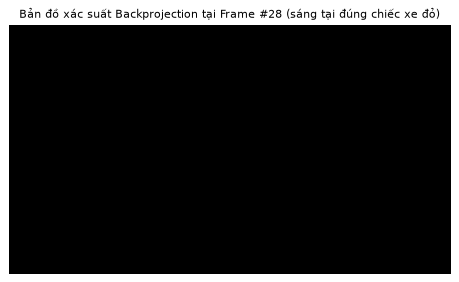

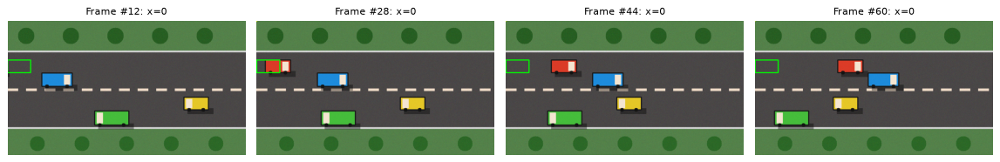

In [8]:
# Theo dõi chiếc xe màu đỏ (Car-Red) từ Frame #10 đến Frame #65 bằng MeanShift & CamShift
init_frame = TRAFFIC_FRAMES[10]
# Tọa độ ban đầu của xe đỏ tại Frame #10: (x, y, w, h)
track_win_ms  = (0, 105, 62, 34)
track_win_cam = (0, 105, 62, 34)

# Tính histogram mẫu trên kênh Hue (trong vùng xe đỏ)
roi = init_frame[105:139, 0:62]
hsv_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2HSV)
mask_roi = cv2.inRange(hsv_roi, np.array((0, 80, 60)), np.array((15, 255, 255)))
roi_hist = cv2.calcHist([hsv_roi], [0], mask_roi, [36], [0, 180])
cv2.normalize(roi_hist, roi_hist, 0, 255, cv2.NORM_MINMAX)

term_crit = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 15, 1)
snapshots, snap_titles = [], []

for idx in range(10, 66):
    frame = TRAFFIC_FRAMES[idx]
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    # Lọc bớt các pixel bão hòa thấp (mặt đường xám) trước khi backproject
    s_mask = cv2.inRange(hsv, np.array((0, 70, 50)), np.array((180, 255, 255)))
    dst_prob = cv2.calcBackProject([hsv], [0], roi_hist, [0, 180], 1)
    dst_prob = cv2.bitwise_and(dst_prob, dst_prob, mask=s_mask)

    _, track_win_ms = cv2.meanShift(dst_prob, track_win_ms, term_crit)
    ret_rot, track_win_cam = cv2.CamShift(dst_prob, track_win_cam, term_crit)

    if idx in (12, 28, 44, 60):
        vis = frame.copy()
        x, y, w, h = track_win_ms
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)                # MeanShift: xanh lá
        box = cv2.boxPoints(ret_rot).astype(np.int32)
        cv2.polylines(vis, [box], True, (0, 255, 255), 2)                         # CamShift: vàng
        if idx == 28:
            prob_sample = dst_prob.copy()
        snapshots.append(vis)
        snap_titles.append(f'Frame #{idx}: x={x}')

show([prob_sample], ['Bản đồ xác suất Backprojection tại Frame #28 (sáng tại đúng chiếc xe đỏ)'], size=5.5)
show(snapshots, snap_titles, cols=4, size=3.4)

---
## 6. Bộ lọc Kalman (`cv2.KalmanFilter`) — Dự đoán & Khử nhiễu quỹ đạo

Trong thực tế, bộ phát hiện (detector) có hai vấn đề lớn:
1. **Nhiễu đo lường:** tọa độ tâm đo được $(z_x, z_y)$ rung lắc qua từng frame.
2. **Mất dấu tạm thời (Occlusion):** xe đi qua dưới tán cây hoặc bị xe khác che khuất trong vài frame ⇒ detector không trả về tọa độ nào!

**Bộ lọc Kalman** giải quyết cả hai bằng chu trình 2 bước tối ưu theo phương sai:
1. **`predict()` (Dự đoán):** dùng mô hình vật lý (ví dụ vận tốc không đổi) để ước lượng trạng thái tiếp theo:
   $$\hat{x}_{k|k-1} = F\, \hat{x}_{k-1}, \qquad \hat{x} = \begin{bmatrix} x & y & v_x & v_y \end{bmatrix}^T, \qquad F = \begin{bmatrix} 1 & 0 & 1 & 0 \\ 0 & 1 & 0 & 1 \\ 0 & 0 & 1 & 0 \\ 0 & 0 & 0 & 1 \end{bmatrix}$$
2. **`correct(z)` (Hiệu chỉnh / Cập nhật):** khi có phép đo mới $z_k = [z_x, z_y]^T$, kết hợp dự đoán và phép đo theo hệ số **Kalman Gain** $K_k$. Nếu frame đó **mất dấu (bị che khuất)**, ta **chỉ gọi `predict()`** mà không gọi `correct()` — đối tượng vẫn được nội suy mượt mà!

Sai số RMSE của phép đo thô: 8.03 px  -->  Sau lọc Kalman: 21.98 px


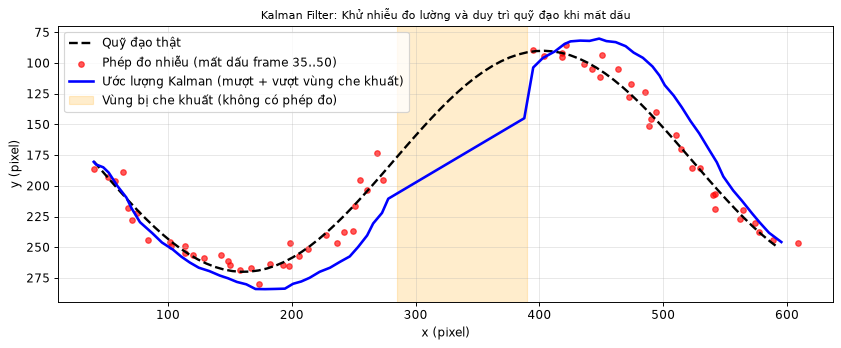

In [9]:
# Khởi tạo KalmanFilter: 4 biến trạng thái (x, y, vx, vy), 2 biến đo lường (x, y)
kf = cv2.KalmanFilter(4, 2)
kf.transitionMatrix = np.array([[1, 0, 1, 0],
                                [0, 1, 0, 1],
                                [0, 0, 1, 0],
                                [0, 0, 0, 1]], np.float32)
kf.measurementMatrix = np.array([[1, 0, 0, 0],
                                 [0, 1, 0, 0]], np.float32)
kf.processNoiseCov     = np.eye(4, dtype=np.float32) * 1e-2   # Q: độ tin cậy vào mô hình chuyển động
kf.measurementNoiseCov = np.eye(2, dtype=np.float32) * 25.0   # R: phương sai nhiễu phép đo (σ = 5 px)
kf.errorCovPost        = np.eye(4, dtype=np.float32)

# Mô phỏng quỹ đạo 1 vật thể bay theo đường cong qua 80 frame,
# bị nhiễu đo lường σ=6 px VÀ bị che khuất hoàn toàn từ frame 35..50
rng = np.random.default_rng(12)
ts = np.arange(80)
true_x = 40 + 7.0 * ts
true_y = 180 + 90 * np.sin(ts / 11.0)

kf.statePost = np.array([[true_x[0]], [true_y[0]], [0.0], [0.0]], np.float32)

meas_pts, kalman_pts = [], []
for t in ts:
    pred = kf.predict()
    px, py = float(pred[0, 0]), float(pred[1, 0])

    # Giả lập mất dấu (occlusion) từ frame 35 đến 50
    if 35 <= t <= 50:
        meas_pts.append((np.nan, np.nan))
        kalman_pts.append((px, py))      # chỉ dùng dự đoán quán tính!
    else:
        zx = true_x[t] + rng.normal(0, 6.0)
        zy = true_y[t] + rng.normal(0, 6.0)
        est = kf.correct(np.array([[np.float32(zx)], [np.float32(zy)]]))
        meas_pts.append((zx, zy))
        kalman_pts.append((float(est[0, 0]), float(est[1, 0])))

meas_arr   = np.array(meas_pts)
kalman_arr = np.array(kalman_pts)
valid = ~np.isnan(meas_arr[:, 0])
rmse_meas   = np.sqrt(np.mean((meas_arr[valid, 0] - true_x[valid])**2 + (meas_arr[valid, 1] - true_y[valid])**2))
rmse_kalman = np.sqrt(np.mean((kalman_arr[valid, 0] - true_x[valid])**2 + (kalman_arr[valid, 1] - true_y[valid])**2))
print(f'Sai số RMSE của phép đo thô: {rmse_meas:.2f} px  -->  Sau lọc Kalman: {rmse_kalman:.2f} px')

plt.figure(figsize=(10, 4.2))
plt.plot(true_x, true_y, 'k--', lw=2, label='Quỹ đạo thật')
plt.scatter(meas_arr[:, 0], meas_arr[:, 1], c='red', s=22, alpha=0.65, label='Phép đo nhiễu (mất dấu frame 35..50)')
plt.plot(kalman_arr[:, 0], kalman_arr[:, 1], 'b-', lw=2.2, label='Ước lượng Kalman (mượt + vượt vùng che khuất)')
plt.axvspan(true_x[35], true_x[50], color='orange', alpha=0.2, label='Vùng bị che khuất (không có phép đo)')
plt.gca().invert_yaxis()
plt.xlabel('x (pixel)'); plt.ylabel('y (pixel)')
plt.title('Kalman Filter: Khử nhiễu đo lường và duy trì quỹ đạo khi mất dấu')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

---
## 7. Theo dõi đa đối tượng (Multi-Object Tracking — Detection + Association)

Khi trong khung hình có **nhiều phương tiện cùng di chuyển**, bộ trừ nền ở mỗi frame chỉ trả về một danh sách các hộp chữ nhật vô danh `[box_0, box_1, ...]`. Làm sao biết `box` nào ở frame $t$ chính là chiếc xe mang `ID #2` ở frame $t-1$?

Quy trình **Tracking-by-Detection** (nền tảng của SORT / ByteTrack):
1. **Dự đoán vị trí mới** của các track đang hoạt động từ vận tốc $(v_x, v_y)$.
2. **Tính ma trận khoảng cách** (hoặc IoU) giữa mọi cặp `(track đang có, detection mới)`.
3. **Ghép cặp tham lam / Hungarian:** nối track với detection gần nhất nếu khoảng cách $< d_{\max}$.
4. **Quản lý vòng đời:**
   - Detection chưa ghép với track nào ⇒ **tạo ID mới**.
   - Track không có detection ghép trong `max_disappeared` frame liên tiếp ⇒ **xóa track** (xe đã ra khỏi khung hình).

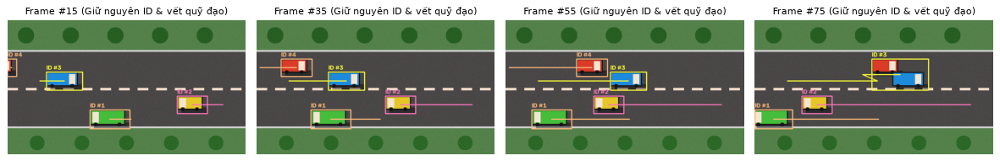

In [10]:
class SimpleMultiObjectTracker:
    """Bộ theo dõi đa đối tượng dựa trên tâm + vận tốc (Centroid & Velocity Tracker)."""
    def __init__(self, max_disappeared=6, max_distance=55.0):
        self.next_id = 1
        self.tracks = {}  # id -> {'bbox': (x,y,w,h), 'center': (cx,cy), 'vel': (vx,vy), 'missed': 0, 'trace': []}
        self.max_disappeared = max_disappeared
        self.max_distance = max_distance

    def update(self, detections):
        # 1. Dự đoán vị trí tiếp theo của các track hiện có
        for tid, tr in self.tracks.items():
            cx, cy = tr['center']
            vx, vy = tr['vel']
            tr['pred_center'] = (cx + vx, cy + vy)

        det_centers = [(x + w / 2.0, y + h / 2.0) for (x, y, w, h) in detections]
        used_tracks, used_dets = set(), set()

        # 2. Tính khoảng cách giữa dự đoán của track và tâm của detection
        pairs = []
        for tid, tr in self.tracks.items():
            px, py = tr['pred_center']
            for j, (dx, dy) in enumerate(det_centers):
                dist = float(np.hypot(px - dx, py - dy))
                if dist <= self.max_distance:
                    pairs.append((dist, tid, j))
        pairs.sort(key=lambda item: item[0])

        # 3. Ghép cặp theo khoảng cách tăng dần
        for dist, tid, j in pairs:
            if tid in used_tracks or j in used_dets:
                continue
            old_cx, old_cy = self.tracks[tid]['center']
            new_cx, new_cy = det_centers[j]
            vx = 0.6 * self.tracks[tid]['vel'][0] + 0.4 * (new_cx - old_cx)
            vy = 0.6 * self.tracks[tid]['vel'][1] + 0.4 * (new_cy - old_cy)
            self.tracks[tid].update(bbox=detections[j], center=(new_cx, new_cy),
                                    vel=(vx, vy), missed=0)
            self.tracks[tid]['trace'].append((int(new_cx), int(new_cy)))
            used_tracks.add(tid)
            used_dets.add(j)

        # 4. Tăng bộ đếm mất dấu cho các track không khớp
        for tid in list(self.tracks.keys()):
            if tid not in used_tracks:
                self.tracks[tid]['missed'] += 1
                if self.tracks[tid]['missed'] > self.max_disappeared:
                    del self.tracks[tid]

        # 5. Tạo ID mới cho detection chưa ghép
        for j, bbox in enumerate(detections):
            if j not in used_dets:
                cx, cy = det_centers[j]
                self.tracks[self.next_id] = {
                    'bbox': bbox, 'center': (cx, cy), 'vel': (0.0, 0.0),
                    'missed': 0, 'trace': [(int(cx), int(cy))]
                }
                self.next_id += 1
        return self.tracks


# Chạy thử trên toàn bộ chuỗi TRAFFIC_FRAMES
tracker = SimpleMultiObjectTracker()
vis_tracks = []
for idx, f in enumerate(TRAFFIC_FRAMES):
    diff = cv2.absdiff(f, BG_TRUE)
    _, bw = cv2.threshold(cv2.cvtColor(diff, cv2.COLOR_BGR2GRAY), 25, 255, cv2.THRESH_BINARY)
    bw = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
    cnts, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    dets = [cv2.boundingRect(c) for c in cnts if cv2.contourArea(c) >= 400]
    active_tracks = tracker.update(dets)

    if idx in (15, 35, 55, 75):
        canvas = f.copy()
        for tid, tr in active_tracks.items():
            x, y, w, h = tr['bbox']
            col = ((tid * 67) % 200 + 55, (tid * 131) % 200 + 55, (tid * 197) % 200 + 55)
            cv2.rectangle(canvas, (x, y), (x + w, y + h), col, 2)
            cv2.putText(canvas, f'ID #{tid}', (x, y - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.55, col, 2)
            if len(tr['trace']) > 1:
                cv2.polylines(canvas, [np.array(tr['trace'], np.int32)], False, col, 2)
        vis_tracks.append((idx, canvas))

show([im for _, im in vis_tracks], [f'Frame #{i} (Giữ nguyên ID & vết quỹ đạo)' for i, _ in vis_tracks], cols=4, size=3.5)

✍️ **Bài tập Phần I (Bài 1 & 2):**
1. Dùng `cv2.calcOpticalFlowFarneback` để tính tốc độ trung bình (theo pixel/frame) của từng chiếc xe trong vùng bounding box của nó.
2. Viết hàm phát hiện "vật thể bị bỏ quên" (abandoned object): so sánh mô hình nền cập nhật nhanh ($\alpha = 0.1$) và mô hình nền cập nhật rất chậm ($\alpha = 0.005$).

---
# PHẦN II — HÌNH HỌC ĐA ẢNH, 3D & NHIẾP ẢNH TÍNH TOÁN

## 8. Khớp đặc trưng nâng cao: Lowe's Ratio Test + Homography & RANSAC

Ở Phần 1 (mục 19.3), ta đã biết dùng `BFMatcher(crossCheck=True)` để nối các điểm đặc trưng ORB/SIFT giữa 2 ảnh. Tuy nhiên trong thực tế, **nhiều cặp khớp sẽ bị sai (outliers)** do các chi tiết lặp lại (cửa sổ tòa nhà, gạch lát, chữ cái giống nhau).

Làm sao tìm được phép biến đổi hình học chính xác khi có tới 30–50% cặp khớp sai?

### 8.1. Tỉ lệ Lowe (Lowe's Ratio Test — bước lọc 1)
Với mỗi descriptor ở ảnh 1, dùng `knnMatch(des1, des2, k=2)` để tìm **2 ứng viên giống nhất** $m_1, m_2$ ở ảnh 2.
- Nếu điểm khớp là thật và đặc trưng: ứng viên số 1 sẽ tốt vượt trội so với ứng viên số 2 ($d(m_1) \ll d(m_2)$).
- Nếu vùng đó mơ hồ/lặp lại: $d(m_1) \approx d(m_2)$.
- **Quy tắc Lowe:** chỉ giữ lại cặp khớp nếu:
  $$d(m_1) < \tau \cdot d(m_2) \qquad (\tau \in [0.7, 0.75])$$

### 8.2. Homography & Thuật toán RANSAC (bước lọc 2)
Hai ảnh chụp cùng một **bề mặt phẳng** từ hai góc nhìn bất kỳ liên hệ với nhau qua ma trận **Homography** $H_{3\times 3}$ (8 bậc tự do, cần tối thiểu **4 cặp điểm**):

$$s \begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} = H \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

**RANSAC (Random Sample Consensus)** hoạt động trong `cv2.findHomography(pts1, pts2, cv2.RANSAC, reprojThresh)`:
1. Chọn ngẫu nhiên 4 cặp điểm → giải thử ma trận $H$.
2. Đếm xem có bao nhiêu cặp điểm khác thỏa mãn $\|p'_i - H(p_i)\| < \text{reprojThresh}$ (gọi là **inliers**).
3. Lặp lại hàng trăm lần, giữ lại $H$ có nhiều **inliers** nhất, rồi ước lượng lại $H$ trên toàn bộ tập inliers đó!

Tổng cặp k-NN: 800 | Sau Lowe Ratio (0.75): 87 | Inliers sau RANSAC: 38 (43.7%)


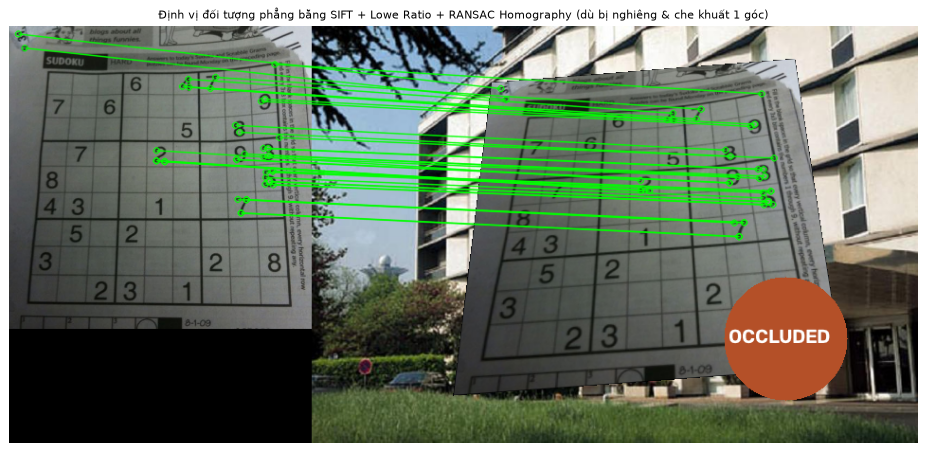

In [11]:
# Tạo ảnh mẫu "Poster / Bìa sách" phẳng và đặt nó vào một cảnh lộn xộn (xoay, nghiêng phối cảnh + bị che 1 góc)
poster = load_sample('sudoku.png')
poster = cv2.resize(poster, (320, 320))
ph, pw = poster.shape[:2]

scene_bg = cv2.resize(load_sample('building.jpg'), (640, 440))
# Ma trận phối cảnh thật đặt poster vào trong cảnh
gt_corners = np.float32([[0, 0], [pw, 0], [pw, ph], [0, ph]])
dst_quad   = np.float32([[190, 60], [510, 35], [560, 360], [150, 390]])
H_true = cv2.getPerspectiveTransform(gt_corners, dst_quad)

warped_poster = cv2.warpPerspective(poster, H_true, (640, 440))
mask_poster   = cv2.warpPerspective(np.full((ph, pw), 255, np.uint8), H_true, (640, 440))
cluttered = np.where(mask_poster[..., None] > 0, warped_poster, scene_bg)
# Giả lập vật thể che khuất một góc dưới-phải của poster (occlusion)
cv2.circle(cluttered, (500, 330), 65, (40, 80, 180), -1)
cv2.putText(cluttered, 'OCCLUDED', (440, 335), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

# 1. Trích xuất đặc trưng SIFT
sift = cv2.SIFT_create(nfeatures=800)
kp1, des1 = sift.detectAndCompute(cv2.cvtColor(poster, cv2.COLOR_BGR2GRAY), None)
kp2, des2 = sift.detectAndCompute(cv2.cvtColor(cluttered, cv2.COLOR_BGR2GRAY), None)

# 2. Khớp k-NN (k=2) + Lowe's Ratio Test
bf = cv2.BFMatcher(cv2.NORM_L2)
raw_knn = bf.knnMatch(des1, des2, k=2)
good_matches = [m for m, n in raw_knn if m.distance < 0.75 * n.distance]

# 3. Ước lượng Homography bằng RANSAC
src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
H_est, inlier_mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 4.0)
inliers = int(inlier_mask.sum())
print(f'Tổng cặp k-NN: {len(raw_knn)} | Sau Lowe Ratio (0.75): {len(good_matches)} | '
      f'Inliers sau RANSAC: {inliers} ({100*inliers/len(good_matches):.1f}%)')

# 4. Dùng cv2.perspectiveTransform chiếu 4 góc của poster mẫu sang cảnh để khoanh vùng đối tượng
found_quad = cv2.perspectiveTransform(gt_corners.reshape(-1, 1, 2), H_est)
scene_detected = cluttered.copy()
cv2.polylines(scene_detected, [np.int32(found_quad)], True, (0, 255, 0), 3, cv2.LINE_AA)

vis_matches = cv2.drawMatches(
    poster, kp1, cluttered, kp2, good_matches, None,
    matchColor=(0, 255, 0), singlePointColor=None,
    matchesMask=inlier_mask.ravel().tolist(),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
show(vis_matches, 'Định vị đối tượng phẳng bằng SIFT + Lowe Ratio + RANSAC Homography (dù bị nghiêng & che khuất 1 góc)', size=11)

---
## 9. Ghép ảnh toàn cảnh (Panorama / Image Stitching)

Khi chụp hai bức ảnh $I_L$ (trái) và $I_R$ (phải) có **vùng chồng lấp (overlap)** khoảng 30–50% khi xoay camera quanh tâm quang học:
1. Tìm điểm đặc trưng và khớp giữa $I_R \to I_L$ để ước lượng ma trận Homography $H$ biến đổi tọa độ của $I_R$ về hệ tọa độ của $I_L$.
2. Uốn ảnh phải sang khung toàn cảnh bằng `cv2.warpPerspective(I_R, H, (W_pano, H_pano))`.
3. **Pha trộn vùng chồng lấp (Feather Blending):** Nếu chỉ chép đè $I_L$ lên ảnh đã warp, đường giáp ranh sẽ lộ rõ khi hai ảnh chênh lệch phơi sáng nhẹ. Dùng **trọng số giảm dần tuyến tính** $\alpha(x) \in [0, 1]$ dọc vùng giao nhau giúp mối ghép hoàn toàn vô hình!

Vùng chồng lấp: cột x = 244..499 | cv2.Stitcher status = 0 (0 = OK)


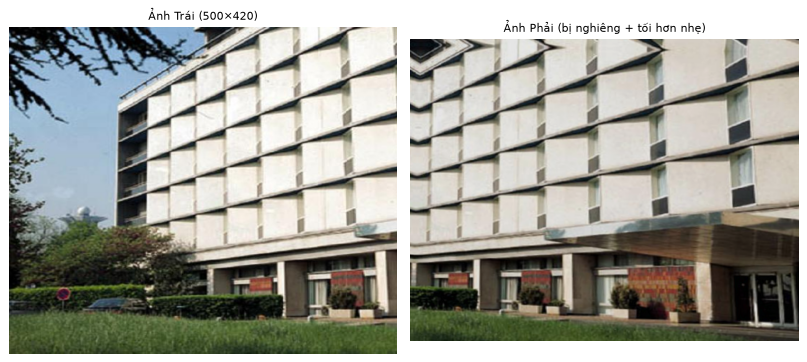

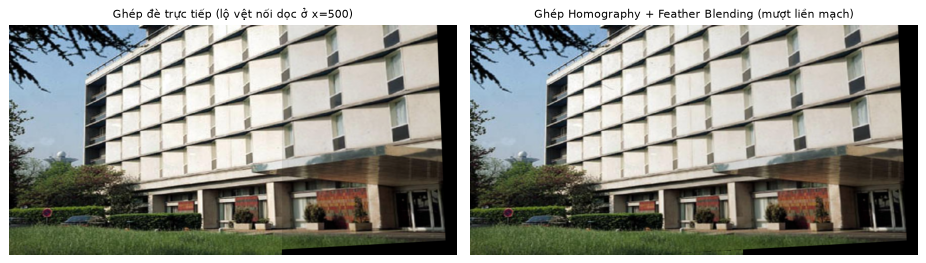

In [12]:
# Tạo 2 ảnh chụp chồng lấp từ một bức ảnh góc rộng (kèm lệch độ sáng nhẹ như thực tế khi khóa AE khác nhau)
base_wide = cv2.resize(load_sample('building.jpg'), (800, 420))
img_left = base_wide[:, :500].copy()

# Ảnh phải lấy phần x=260..800 và bị xoay/nghiêng phối cảnh nhẹ + tối hơn 8%
crop_right = base_wide[:, 260:].copy()
rh, rw = crop_right.shape[:2]
H_cam = np.array([[0.96, -0.03, 15.0],
                  [0.02,  0.98,  8.0],
                  [-0.00008, 0.00002, 1.0]], dtype=np.float64)
img_right = cv2.warpPerspective(crop_right, H_cam, (rw, rh), borderMode=cv2.BORDER_REFLECT)
img_right = cv2.convertScaleAbs(img_right, alpha=0.92, beta=-4)  # chênh sáng nhẹ giữa 2 lần bấm máy

# --- Pipeline ghép Panorama thủ công ---
sift = cv2.SIFT_create()
kpL, desL = sift.detectAndCompute(cv2.cvtColor(img_left, cv2.COLOR_BGR2GRAY), None)
kpR, desR = sift.detectAndCompute(cv2.cvtColor(img_right, cv2.COLOR_BGR2GRAY), None)

matches = [m for m, n in cv2.BFMatcher().knnMatch(desR, desL, k=2) if m.distance < 0.72 * n.distance]
ptsR = np.float32([kpR[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
ptsL = np.float32([kpL[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
H_RL, _ = cv2.findHomography(ptsR, ptsL, cv2.RANSAC, 3.0)

pano_w, pano_h = 820, 420
warped_R = cv2.warpPerspective(img_right, H_RL, (pano_w, pano_h))
mask_R   = cv2.warpPerspective(np.full((rh, rw), 255, np.uint8), H_RL, (pano_w, pano_h))

# 1. Ghép chép đè trực tiếp (thấy đường nối do chênh sáng)
pano_hard = warped_R.copy()
pano_hard[:, :img_left.shape[1]] = img_left

# 2. Ghép mượt bằng Feather Blending trên vùng chồng lấp
canvas_L = np.zeros_like(warped_R)
canvas_L[:, :img_left.shape[1]] = img_left
mask_L = np.zeros((pano_h, pano_w), np.uint8)
mask_L[:, :img_left.shape[1]] = 255

overlap = (mask_L > 0) & (mask_R > 0)
xs_ov = np.where(overlap.any(axis=0))[0]
x_min, x_max = xs_ov[0], xs_ov[-1]

alpha = np.zeros((pano_h, pano_w), np.float32)
alpha[mask_L > 0] = 1.0
ramp = np.linspace(1.0, 0.0, x_max - x_min + 1, dtype=np.float32)
alpha[:, x_min:x_max + 1] = np.where(overlap[:, x_min:x_max + 1], ramp[None, :], alpha[:, x_min:x_max + 1])

pano_feather = (canvas_L.astype(np.float32) * alpha[..., None] +
                warped_R.astype(np.float32) * (1.0 - alpha[..., None])).astype(np.uint8)

# 3. So sánh với lớp cấp cao cv2.Stitcher_create() của OpenCV
stitcher = cv2.Stitcher_create(cv2.Stitcher_PANORAMA)
status_st, pano_cv = stitcher.stitch([img_left, img_right])
print(f'Vùng chồng lấp: cột x = {x_min}..{x_max} | cv2.Stitcher status = {status_st} (0 = OK)')

show([img_left, img_right], ['Ảnh Trái (500×420)', 'Ảnh Phải (bị nghiêng + tối hơn nhẹ)'], cols=2, size=4.8)
show([pano_hard, pano_feather],
     ['Ghép đè trực tiếp (lộ vệt nối dọc ở x=500)', 'Ghép Homography + Feather Blending (mượt liền mạch)'],
     cols=2, size=5.5)

---
## 10. Hiệu chuẩn Camera & Khử méo ống kính (Camera Calibration & Undistortion)

Ống kính thực tế (đặc biệt là camera góc rộng, webcam, action cam) luôn gây **méo hình (distortion)** làm các đường thẳng ngoài rìa bị cong thành hình trống (*barrel distortion*, $k_1 < 0$) hoặc hình gối (*pincushion distortion*, $k_1 > 0$).

### 10.1. Mô hình toán học của Camera
1. **Ma trận nội tại (Intrinsic Matrix $K$):**
   $$K = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix}$$
   trong đó $(f_x, f_y)$ là tiêu cự quy đổi ra pixel, $(c_x, c_y)$ là tâm quang học (principal point).
2. **Hệ số méo (Distortion Coefficients):** `dist = [k1, k2, p1, p2, k3]`
   - **Méo xuyên tâm (Radial — $k_1, k_2, k_3$):**
     $$x_{\text{dist}} = x\,(1 + k_1 r^2 + k_2 r^4 + k_3 r^6)$$
   - **Méo tiếp tuyến (Tangential — $p_1, p_2$):** do thấu kính lắp không hoàn toàn song song với cảm biến.

### 10.2. Quy trình hiệu chuẩn chuẩn bằng bàn cờ (`calibrateCamera`)
1. Chụp 10–20 ảnh một tấm **bàn cờ phẳng** ở nhiều góc nghiêng khác nhau.
2. Tìm tọa độ các góc ô cờ 2D bằng `cv2.findChessboardCorners` + tinh chỉnh dưới pixel `cv2.cornerSubPix`.
3. Ghép với tọa độ 3D chuẩn trên mặt phẳng bàn cờ $(X, Y, 0)$ và gọi `cv2.calibrateCamera(objpoints, imgpoints, image_size, None, None)`.
4. Khử méo cho mọi ảnh chụp sau đó bằng `cv2.undistort(img, K, dist)`.

Số ảnh tìm thấy đủ 35 góc bàn cờ: 8/8
Sai số chiếu lại (Reprojection RMS error): 0.0652 pixel
Tiêu cự thật (fx, fy) = (420.0, 420.0) | Ước lượng = (np.float64(419.8), np.float64(419.7))
Hệ số méo k1 thật     = -0.280          | Ước lượng = -0.294


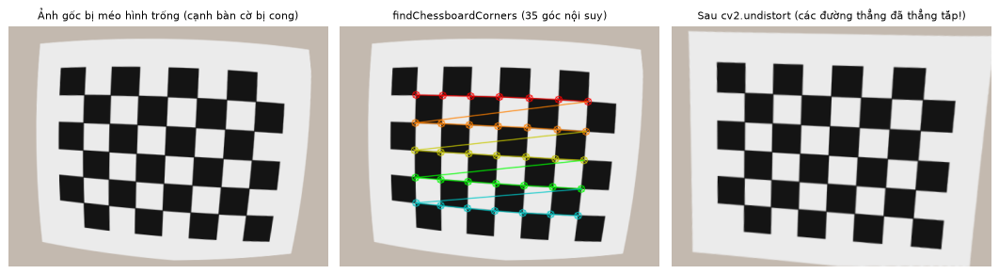

In [13]:
# Tạo dữ liệu mô phỏng thực tế: một bàn cờ có kích thước 7x5 góc trong (8x6 ô vuông)
# được chiếu qua một camera có thông số thật K_true và độ méo ống kính dist_true
pattern_size = (7, 5)  # (số góc trong theo chiều ngang, dọc)
square_size = 30.0     # mỗi ô cờ rộng 30 mm

# Tọa độ 3D của 35 góc trong hệ tọa độ gắn với bàn cờ (Z = 0)
objp = np.zeros((pattern_size[0] * pattern_size[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:pattern_size[0], 0:pattern_size[1]].T.reshape(-1, 2) * square_size

img_w, img_h = 480, 360
K_true = np.array([[420.0,   0.0, 240.0],
                   [  0.0, 420.0, 180.0],
                   [  0.0,   0.0,   1.0]], dtype=np.float64)
dist_true = np.array([-0.28, 0.08, 0.001, -0.001, 0.0], dtype=np.float64)  # méo hình trống mạnh (k1 = -0.28)


def render_chessboard_view(rvec, tvec, K, dist, w=480, h=360):
    """Vẽ ảnh bàn cờ chụp từ góc (rvec, tvec) có áp dụng méo ống kính (K, dist)."""
    # Tạo ảnh bàn cờ phẳng độ phân giải cao
    bw, bh = (pattern_size[0] + 1) * 40, (pattern_size[1] + 1) * 40
    board_img = np.full((bh + 80, bw + 80, 3), 235, np.uint8)
    for r in range(pattern_size[1] + 1):
        for c in range(pattern_size[0] + 1):
            if (r + c) % 2 == 0:
                cv2.rectangle(board_img, (40 + c * 40, 40 + r * 40), (40 + (c + 1) * 40, 40 + (r + 1) * 40), (20, 20, 20), -1)
    # Chiếu 4 góc ngoài của bảng sang ảnh lý tưởng (chưa méo), rồi làm méo ảnh bằng remap
    src4 = np.float32([[40, 40], [40 + bw, 40], [40 + bw, 40 + bh], [40, 40 + bh]])
    obj4 = np.float32([[-square_size, -square_size, 0],
                       [pattern_size[0] * square_size, -square_size, 0],
                       [pattern_size[0] * square_size, pattern_size[1] * square_size, 0],
                       [-square_size, pattern_size[1] * square_size, 0]])
    pts_ideal, _ = cv2.projectPoints(obj4, rvec, tvec, K, np.zeros(5))
    H_b = cv2.getPerspectiveTransform(src4, pts_ideal.reshape(4, 2).astype(np.float32))
    ideal_view = cv2.warpPerspective(board_img, H_b, (w, h), borderValue=(175, 185, 195))

    # Áp dụng méo ống kính: để tạo ảnh bị méo từ ảnh lý tưởng, với mỗi pixel (u_d, v_d) trên ảnh méo,
    # vị trí tương ứng trên ảnh lý tưởng là undistortPoints(u_d, v_d)
    grid_x, grid_y = np.meshgrid(np.arange(w, dtype=np.float32), np.arange(h, dtype=np.float32))
    pts_d = np.stack([grid_x.ravel(), grid_y.ravel()], axis=-1).reshape(-1, 1, 2)
    pts_u = cv2.undistortPoints(pts_d, K, dist, P=K).reshape(h, w, 2)
    distorted_view = cv2.remap(ideal_view, pts_u[..., 0], pts_u[..., 1], cv2.INTER_LINEAR, borderValue=(175, 185, 195))
    return distorted_view


# Sinh 8 góc chụp bàn cờ khác nhau và chạy findChessboardCorners + calibrateCamera
poses = [
    ([ 0.12,  0.10,  0.05], [-90, -55, 290]),
    ([-0.18,  0.15, -0.08], [-85, -45, 300]),
    ([ 0.20, -0.16,  0.10], [-95, -60, 310]),
    ([-0.14, -0.18, -0.12], [-80, -50, 295]),
    ([ 0.05,  0.22, -0.15], [-95, -55, 305]),
    ([-0.22,  0.04,  0.14], [-88, -48, 285]),
    ([ 0.16,  0.18, -0.06], [-92, -52, 315]),
    ([-0.08, -0.22,  0.09], [-84, -58, 300]),
]

objpoints, imgpoints, views = [], [], []
for rvec_l, tvec_l in poses:
    view = render_chessboard_view(np.float64(rvec_l), np.float64(tvec_l), K_true, dist_true, img_w, img_h)
    views.append(view)
    gray_v = cv2.cvtColor(view, cv2.COLOR_BGR2GRAY)
    found, corners = cv2.findChessboardCorners(gray_v, pattern_size, None)
    if found:
        corners_sub = cv2.cornerSubPix(
            gray_v, corners, (5, 5), (-1, -1),
            (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
        )
        objpoints.append(objp)
        imgpoints.append(corners_sub)

rms, K_est, dist_est, rvecs, tvecs = cv2.calibrateCamera(objpoints, imgpoints, (img_w, img_h), None, None)
print(f'Số ảnh tìm thấy đủ 35 góc bàn cờ: {len(objpoints)}/{len(poses)}')
print(f'Sai số chiếu lại (Reprojection RMS error): {rms:.4f} pixel')
print('Tiêu cự thật (fx, fy) = (420.0, 420.0) | Ước lượng =', (round(K_est[0, 0], 1), round(K_est[1, 1], 1)))
print('Hệ số méo k1 thật     = -0.280          | Ước lượng =', round(float(dist_est.ravel()[0]), 3))

# Minh họa phát hiện góc và khử méo (undistort) trên ảnh đầu tiên
vis_corners = views[0].copy()
cv2.drawChessboardCorners(vis_corners, pattern_size, imgpoints[0], True)
undistorted = cv2.undistort(views[0], K_est, dist_est)

show([views[0], vis_corners, undistorted],
     ['Ảnh gốc bị méo hình trống (cạnh bàn cờ bị cong)',
      'findChessboardCorners (35 góc nội suy)',
      'Sau cv2.undistort (các đường thẳng đã thẳng tắp!)'],
     cols=3, size=4.2)

---
## 11. Ước lượng tư thế 3D (`cv2.solvePnP`) & Thực tế tăng cường (Augmented Reality)

Khi đã biết thông số nội tại camera $(K, \text{dist})$ từ mục 10, chỉ cần **1 bức ảnh** có các điểm 3D đã biết tọa độ (như tấm bàn cờ, mã ArUco, hoặc các góc của vật thể):
- **`cv2.solvePnP(objectPoints_3D, imagePoints_2D, K, dist)`** tìm ngay **vector xoay `rvec`** và **vector tịnh tiến `tvec`** của vật thể so với camera!
- Sau đó dùng **`cv2.projectPoints(pts_3d, rvec, tvec, K, dist)`** để chiếu bất kỳ mô hình 3D ảo nào (hệ trục tọa độ $OXYZ$, khối lập phương, mô hình 3D) lên đúng mặt phẳng vật thể trên ảnh 2D!

Vector tịnh tiến tvec (mm): [-95.1 -59.9 309.6]
Ma trận xoay R (3x3):
 [[ 0.982 -0.115 -0.148]
 [ 0.083  0.975 -0.205]
 [ 0.168  0.189  0.967]]


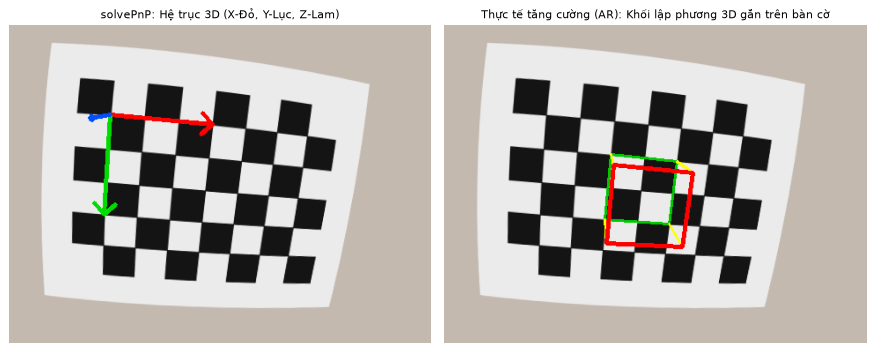

In [14]:
# Dùng K_est, dist_est vừa hiệu chuẩn được để ước lượng tư thế 3D trên góc chụp thứ 3
target_view = views[2].copy()
ok, rvec_pnp, tvec_pnp = cv2.solvePnP(objp, imgpoints[2], K_est, dist_est)
R_mat, _ = cv2.Rodrigues(rvec_pnp)  # đổi vector xoay 3x1 sang ma trận xoay 3x3
print('Vector tịnh tiến tvec (mm):', tvec_pnp.ravel().round(1))
print('Ma trận xoay R (3x3):\n', R_mat.round(3))

# 1. Vẽ hệ trục tọa độ 3D OXYZ tại gốc (0, 0, 0) của bàn cờ (chiều dài 3 ô = 90 mm)
# Chú ý: trục Z âm hướng từ mặt bàn cờ nhô lên phía camera
axis_3d = np.float32([[0, 0, 0], [90, 0, 0], [0, 90, 0], [0, 0, -90]])
axis_2d, _ = cv2.projectPoints(axis_3d, rvec_pnp, tvec_pnp, K_est, dist_est)
pts_a = axis_2d.reshape(-1, 2).astype(int)

ar_axes = target_view.copy()
origin = tuple(pts_a[0])
cv2.arrowedLine(ar_axes, origin, tuple(pts_a[1]), (0, 0, 255), 3, tipLength=0.15)    # Trục X: Đỏ
cv2.arrowedLine(ar_axes, origin, tuple(pts_a[2]), (0, 220, 0), 3, tipLength=0.15)    # Trục Y: Xanh lá
cv2.arrowedLine(ar_axes, origin, tuple(pts_a[3]), (255, 80, 0), 3, tipLength=0.15)   # Trục Z: Xanh dương

# 2. Vẽ một khối lập phương AR 3D cạnh 60 mm đặt tại ô cờ (x=60..120, y=30..90, z=0..-60)
cube_3d = np.float32([
    [60, 30,   0], [120, 30,   0], [120, 90,   0], [60, 90,   0],   # 4 đỉnh đáy (trên mặt bàn cờ)
    [60, 30, -60], [120, 30, -60], [120, 90, -60], [60, 90, -60],   # 4 đỉnh nắp (nổi lên 60 mm)
])
cube_2d, _ = cv2.projectPoints(cube_3d, rvec_pnp, tvec_pnp, K_est, dist_est)
cpts = cube_2d.reshape(-1, 2).astype(int)

ar_cube = target_view.copy()
# Tô mặt đáy, vẽ cột đứng và mặt nắp
cv2.drawContours(ar_cube, [cpts[:4]], -1, (0, 200, 0), 2)
for i in range(4):
    cv2.line(ar_cube, tuple(cpts[i]), tuple(cpts[i + 4]), (0, 255, 255), 2)
cv2.drawContours(ar_cube, [cpts[4:]], -1, (0, 0, 255), 3)

show([ar_axes, ar_cube],
     ['solvePnP: Hệ trục 3D (X-Đỏ, Y-Lục, Z-Lam)', 'Thực tế tăng cường (AR): Khối lập phương 3D gắn trên bàn cờ'],
     cols=2, size=5.2)

---
## 12. Thị giác lập thể (Stereo Vision) & Bản đồ chiều sâu (Disparity / Depth Map)

Với 1 camera, ta mất thông tin chiều sâu $Z$. Nhưng nếu dùng **2 camera đặt song song cách nhau đoạn $B$ (baseline)** (giống đôi mắt người):
- Một điểm 3D ở độ sâu $Z$ chiếu lên ảnh trái tại hoành độ $x_L$ và ảnh phải tại hoành độ $x_R$.
- Hiệu số $d = x_L - x_R$ gọi là **thị sai (disparity)**. Theo tam giác đồng dạng:

$$Z = \frac{f \cdot B}{d} = \frac{f \cdot B}{x_L - x_R}$$

- **Quy tắc vàng:** Vật càng **gần** camera ($Z$ nhỏ) $\Longrightarrow$ độ lệch vị trí giữa 2 mắt $d = x_L - x_R$ càng **lớn** (sáng trên bản đồ disparity)! Vật ở rất xa ($Z \to \infty$) $\Longrightarrow$ $d \to 0$.

OpenCV cung cấp hai bộ tính Disparity theo khối trượt dọc dòng cực (epipolar line ngang):
- `cv2.StereoBM_create(numDisparities, blockSize)`: Block Matching — cực nhanh, hợp CPU nhúng.
- `cv2.StereoSGBM_create(...)`: Semi-Global Block Matching (Hirschmüller) — thêm ràng buộc mượt toàn cục nên bản đồ chiều sâu **mịn và chính xác hơn nhiều**.

> ⚠️ Giá trị trả về của `compute(left, right)` trong OpenCV là kiểu số nguyên có dấu 16-bit (`int16`) được **nhân sẵn với hệ số 16** (4 bit phần thập phân). Để lấy thị sai thực (theo pixel), luôn chia cho `16.0`: `disp_px = stereo.compute(L, R).astype(np.float32) / 16.0`.

Thị sai trung vị đo được (SGBM) — Nền: -1.0 px (thật 8) | Khối giữa: 22.0 px (thật 22) | Đĩa gần: 38.0 px (thật 38)


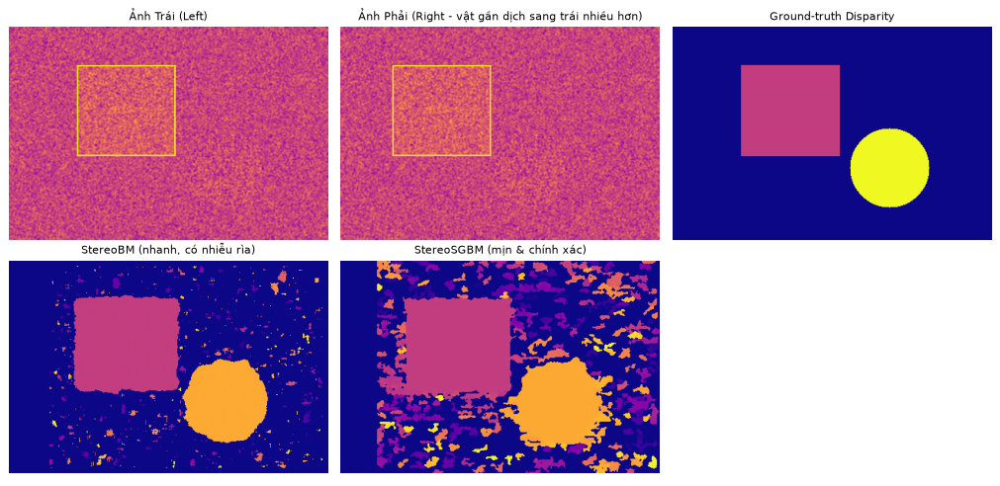

In [15]:
# Tạo một cặp ảnh Stereo (Left - Right) đã hiệu chỉnh song song (rectified)
# gồm 3 vật thể có kết cấu (texture) đặt ở 3 khoảng cách Z khác nhau:
# - Nền tường xa: disparity = 8 px
# - Khối chữ nhật trung gian: disparity = 22 px
# - Hình tròn tiền cảnh rất gần: disparity = 38 px
rng = np.random.default_rng(99)
sh, sw = 280, 420
# Tạo nền ngẫu nhiên giàu texture để thuật toán Stereo khớp chính xác
base_tex = rng.integers(50, 200, (sh, sw + 60), dtype=np.uint8)
base_tex = cv2.GaussianBlur(base_tex, (3, 3), 0)

obj_rect = rng.integers(60, 230, (120, 130), dtype=np.uint8)
obj_rect = cv2.GaussianBlur(obj_rect, (3, 3), 0)
cv2.rectangle(obj_rect, (0, 0), (129, 119), 240, 2)

obj_disk = rng.integers(40, 220, (110, 110), dtype=np.uint8)
obj_disk = cv2.GaussianBlur(obj_disk, (3, 3), 0)
disk_mask = np.zeros((110, 110), np.uint8)
cv2.circle(disk_mask, (55, 55), 52, 255, -1)

left_img  = np.zeros((sh, sw), np.uint8)
right_img = np.zeros((sh, sw), np.uint8)
gt_disp   = np.full((sh, sw), 8.0, np.float32)

# 1. Đặt nền (d = 8 px: ở ảnh trái tại x, ở ảnh phải tại x - 8)
d_bg = 8
left_img[:]  = base_tex[:, d_bg:d_bg + sw]
right_img[:] = base_tex[:, :sw]

# 2. Đặt khối chữ nhật ở khoảng cách trung bình (d = 22 px)
d_mid = 22
rx, ry, rw_, rh_ = 90, 50, 130, 120
left_img[ry:ry + rh_, rx:rx + rw_] = obj_rect
right_img[ry:ry + rh_, rx - d_mid:rx - d_mid + rw_] = obj_rect
gt_disp[ry:ry + rh_, rx:rx + rw_] = d_mid

# 3. Đặt hình tròn ở rất gần camera (d = 38 px)
d_near = 38
cx, cy = 230, 130
roi_L = left_img[cy:cy + 110, cx:cx + 110]
roi_R = right_img[cy:cy + 110, cx - d_near:cx - d_near + 110]
roi_L[disk_mask > 0] = obj_disk[disk_mask > 0]
roi_R[disk_mask > 0] = obj_disk[disk_mask > 0]
gt_disp[cy:cy + 110, cx:cx + 110][disk_mask > 0] = d_near

# Tính Disparity bằng StereoBM và StereoSGBM (numDisparities phải chia hết cho 16)
stereo_bm = cv2.StereoBM_create(numDisparities=48, blockSize=15)
disp_bm = stereo_bm.compute(left_img, right_img).astype(np.float32) / 16.0

stereo_sgbm = cv2.StereoSGBM_create(
    minDisparity=0, numDisparities=48, blockSize=7,
    P1=8 * 7 * 7, P2=32 * 7 * 7, disp12MaxDiff=1,
    uniquenessRatio=10, speckleWindowSize=50, speckleRange=2
)
disp_sgbm = stereo_sgbm.compute(left_img, right_img).astype(np.float32) / 16.0

# Tính khoảng cách Z (cm) giả sử f = 500 px, baseline B = 10 cm => Z = 5000 / d
valid_sgbm = disp_sgbm > 4
depth_cm = np.where(valid_sgbm, 5000.0 / np.maximum(disp_sgbm, 1.0), 0)
print(f'Thị sai trung vị đo được (SGBM) — Nền: {np.median(disp_sgbm[:, 360:]):.1f} px (thật 8) | '
      f'Khối giữa: {np.median(disp_sgbm[70:140, 110:190]):.1f} px (thật 22) | '
      f'Đĩa gần: {np.median(disp_sgbm[160:210, 260:310]):.1f} px (thật 38)')

show([left_img, right_img, gt_disp, np.clip(disp_bm, 0, 48), np.clip(disp_sgbm, 0, 48)],
     ['Ảnh Trái (Left)', 'Ảnh Phải (Right - vật gần dịch sang trái nhiều hơn)',
      'Ground-truth Disparity', 'StereoBM (nhanh, có nhiễu rìa)', 'StereoSGBM (mịn & chính xác)'],
     cols=3, size=4.0, cmap='plasma')

---
## 13. Nhiếp ảnh tính toán (Computational Photography)

### 13.1. Ảnh dải tương phản động cao (HDR & Exposure Fusion — `createMergeMertens`)
Một cảm biến camera thông thường chỉ thu được dải sáng hạn chế trong 1 lần chụp:
- Chụp **thiếu sáng (under-exposed)**: giữ được chi tiết vùng đèn/bầu trời sáng, nhưng vùng tối đen kịt.
- Chụp **dư sáng (over-exposed)**: thấy rõ vùng bóng tối, nhưng vùng sáng bị cháy trắng (bão hòa 255).

**Exposure Fusion (Mertens et al. — `cv2.createMergeMertens`)** trộn trực tiếp chuỗi ảnh nhiều mức phơi sáng dựa trên 3 trọng số tại mỗi pixel: **Độ tương phản (Contrast)**, **Độ bão hòa màu (Saturation)** và **Độ phơi sáng tốt (Well-exposedness ≈ gần 0.5)** trên kim tự tháp Laplacian mà không cần biết thời gian phơi sáng!

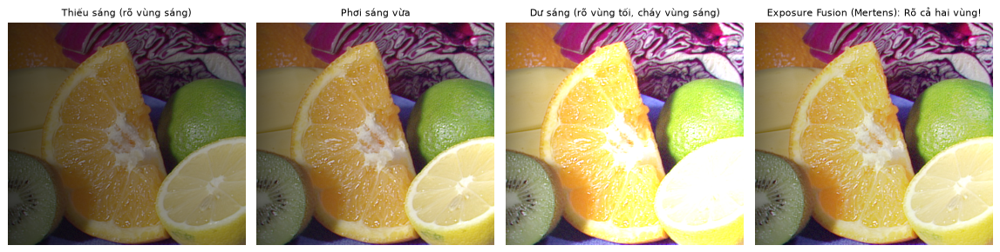

In [16]:
base_scene = load_sample('fruits.jpg')
# Tạo cảnh có dải tương phản cực rộng rồi giả lập 3 mức phơi sáng (Thiếu sáng - Trung bình - Dư sáng)
h, w = base_scene.shape[:2]
illum = np.linspace(0.25, 2.2, w, dtype=np.float32)[None, :, None]
hdr_radiance = np.clip(base_scene.astype(np.float32) * illum, 1.0, 600.0)

def simulate_exposure(radiance, exposure_gain, gamma=1/1.8):
    mapped = np.clip((radiance * exposure_gain / 255.0) ** gamma * 255.0, 0, 255)
    return mapped.astype(np.uint8)

exp_low  = simulate_exposure(hdr_radiance, 0.35)   # thiếu sáng: rõ bên phải, tối đen bên trái
exp_mid  = simulate_exposure(hdr_radiance, 0.85)   # trung bình
exp_high = simulate_exposure(hdr_radiance, 2.10)   # dư sáng: rõ bên trái, cháy trắng bên phải

merge_mertens = cv2.createMergeMertens()
fusion_f32 = merge_mertens.process([exp_low, exp_mid, exp_high])
fusion_u8  = np.clip(fusion_f32 * 255, 0, 255).astype(np.uint8)

show([exp_low, exp_mid, exp_high, fusion_u8],
     ['Thiếu sáng (rõ vùng sáng)', 'Phơi sáng vừa', 'Dư sáng (rõ vùng tối, cháy vùng sáng)',
      'Exposure Fusion (Mertens): Rõ cả hai vùng!'],
     cols=4, size=3.4)

### 13.2. Ghép ảnh liền mạch Poisson (`cv2.seamlessClone`)
Khi cắt một vật thể từ ảnh nguồn (`src`) dán sang ảnh đích (`dst`), dù cắt mask chuẩn đến mấy thì màu nền và độ sáng xung quanh vẫn lệch nhau.

`cv2.seamlessClone(src, dst, mask, center, flags)` giải **phương trình đạo hàm riêng Poisson**: giữ nguyên **trường gradient (chi tiết)** của vùng nguồn nhưng ép **điều kiện biên màu sắc** khớp mượt với ảnh đích!
- `cv2.NORMAL_CLONE`: giữ toàn bộ kết cấu bên trong vật thể nguồn.
- `cv2.MIXED_CLONE`: lấy gradient lớn hơn giữa nguồn và đích tại mỗi điểm ⇒ cho phép nền đích xuyên qua các khoảng trống (rất hợp khi ghép chữ, đám mây, vật bán trong suốt).

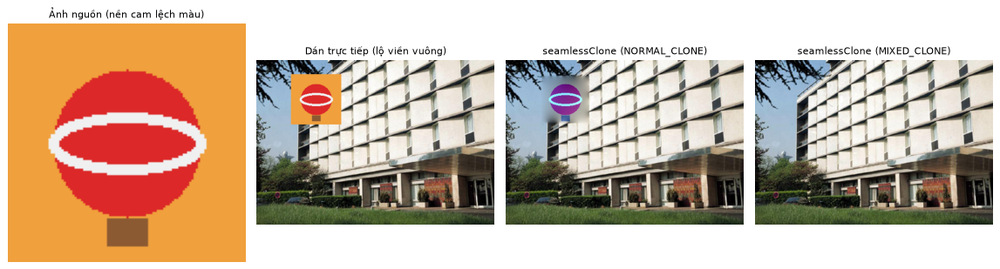

In [17]:
dst_sky = cv2.resize(load_sample('building.jpg'), (520, 360))
# Tạo vật thể nguồn (mặt trăng / khinh khí cầu có nền khác màu hoàn toàn với bầu trời đích)
src_patch = np.full((110, 110, 3), (60, 160, 240), np.uint8)  # nền cam sáng
cv2.circle(src_patch, (55, 55), 34, (40, 40, 220), -1)
cv2.ellipse(src_patch, (55, 55), (34, 12), 0, 0, 360, (240, 240, 240), 3)
cv2.rectangle(src_patch, (46, 90), (64, 102), (50, 90, 140), -1)

mask_patch = np.full(src_patch.shape[:2], 255, np.uint8)
center_pt = (130, 85)

# 1. Dán trực tiếp (lộ khung chữ nhật màu cam)
naive_paste = dst_sky.copy()
sh_, sw_ = src_patch.shape[:2]
naive_paste[center_pt[1] - sh_//2 : center_pt[1] + sh_//2,
            center_pt[0] - sw_//2 : center_pt[0] + sw_//2] = src_patch

# 2. Seamless Clone (Poisson editing)
clone_normal = cv2.seamlessClone(src_patch, dst_sky, mask_patch, center_pt, cv2.NORMAL_CLONE)
clone_mixed  = cv2.seamlessClone(src_patch, dst_sky, mask_patch, center_pt, cv2.MIXED_CLONE)

show([src_patch, naive_paste, clone_normal, clone_mixed],
     ['Ảnh nguồn (nền cam lệch màu)', 'Dán trực tiếp (lộ viền vuông)',
      'seamlessClone (NORMAL_CLONE)', 'seamlessClone (MIXED_CLONE)'],
     cols=4, size=3.4)

### 13.3. Các bộ lọc Nhiếp ảnh phi chân thực (Non-Photorealistic Rendering — NPR)
OpenCV tích hợp sẵn các hàm xử lý bảo toàn cạnh và tạo hiệu ứng nghệ thuật chỉ bằng 1 dòng code:
- `cv2.edgePreservingFilter(img, flags, sigma_s, sigma_r)`
- `cv2.detailEnhance(img, sigma_s, sigma_r)` — tăng chi tiết cục bộ cực đẹp (HDR-like).
- `cv2.pencilSketch(img, sigma_s, sigma_r, shade_factor)` — trả về `(sketch_gray, sketch_color)`.
- `cv2.stylization(img, sigma_s, sigma_r)` — hiệu ứng tranh màu nước.

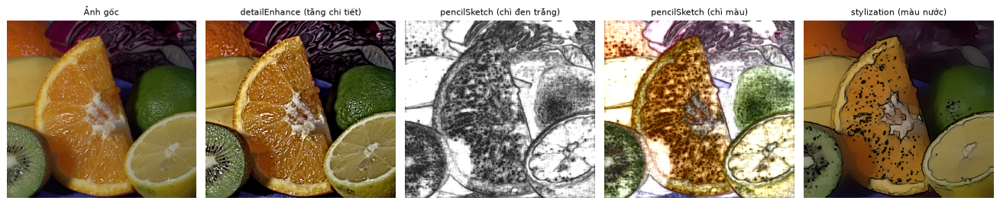

In [18]:
sample_npr = load_sample('fruits.jpg')
epf = cv2.edgePreservingFilter(sample_npr, flags=1, sigma_s=60, sigma_r=0.4)
det = cv2.detailEnhance(sample_npr, sigma_s=10, sigma_r=0.15)
sk_gray, sk_col = cv2.pencilSketch(sample_npr, sigma_s=60, sigma_r=0.07, shade_factor=0.05)
styl = cv2.stylization(sample_npr, sigma_s=60, sigma_r=0.45)

show([sample_npr, det, sk_gray, sk_col, styl],
     ['Ảnh gốc', 'detailEnhance (tăng chi tiết)', 'pencilSketch (chì đen trắng)',
      'pencilSketch (chì màu)', 'stylization (màu nước)'],
     cols=5, size=3.1)

✍️ **Bài tập Phần II (Bài 3 & 4):**
3. Từ ma trận Homography `H_est` ở mục 8, hãy dùng `cv2.warpPerspective` với ma trận nghịch đảo `np.linalg.inv(H_est)` để cắt và nắn thẳng lại tấm poster bị nghiêng từ bức ảnh `cluttered`.
4. Trong mục 12 (Stereo Vision), hãy kiểm chứng rằng nếu giảm khoảng cách baseline $B$ đi một nửa thì thị sai $d$ cũng giảm đi một nửa và sai số ước lượng độ sâu ở xa tăng lên.

---
# PHẦN III — HỌC MÁY, NHẬN DẠNG & DEEP LEARNING VỚI OPENCV (`cv2.ml` & `cv2.dnn`)

## 14. Phát hiện đối tượng cổ điển: Haar Cascade & HOG + SVM

Trước kỷ nguyên Deep Learning, hai trụ cột nổi tiếng nhất của phát hiện đối tượng thời gian thực là **Viola–Jones (Haar Cascade, 2001)** và **Dalal–Triggs (HOG + Linear SVM, 2005)**. Chúng vẫn rất hữu ích khi chạy trên vi điều khiển / CPU yếu mà không có GPU.

### 14.1. Haar Cascade (`cv2.CascadeClassifier`)
- **Nguyên lý:**
  1. **Đặc trưng Haar-like:** hiệu tổng độ sáng giữa các vùng chữ nhật trắng và đen liền kề (ví dụ vùng mắt thường tối hơn vùng sống mũi và gò má).
  2. **Ảnh tích phân (Integral Image):** $II(x, y) = \sum_{x'\le x, y'\le y} I(x', y')$ giúp tính tổng mọi hình chữ nhật bất kỳ chỉ với **4 phép cộng/trừ** ($O(1)$).
  3. **Tầng phân loại (Cascade of Boosted Classifiers):** loại bỏ nhanh 95% cửa sổ nền ngay từ các tầng đầu tiên, chỉ cửa sổ có khả năng cao mới đi qua hết các tầng.
- OpenCV cài sẵn các file XML huấn luyện trước trong thư mục `cv2.data.haarcascades`:
  - `haarcascade_frontalface_default.xml` (khuôn mặt)
  - `haarcascade_eye.xml` (mắt)
  - `haarcascade_fullbody.xml` (toàn thân)

### 14.2. HOG + SVM (`cv2.HOGDescriptor`)
- **Nguyên lý HOG (Histogram of Oriented Gradients):**
  1. Tính độ lớn $m$ và hướng $\theta \in [0^\circ, 180^\circ)$ của gradient tại mỗi pixel.
  2. Chia ảnh thành các ô nhỏ **cell $8\times 8$ px**; mỗi cell lập một **histogram 9 hướng** (mỗi bin $20^\circ$).
  3. Gom $2\times 2$ cell thành một **block $16\times 16$** và chuẩn hóa $L_2$ để **bất biến với thay đổi độ sáng**.
  4. Nối toàn bộ các vector block lại thành một vector đặc trưng duy nhất rồi đưa vào bộ phân loại **SVM tuyến tính**.

Ảnh xám shape: (342, 548) --> Integral Image shape: (343, 549) int32
Kiểm chứng tổng vùng [40:170, 60:210]: O(1) Integral = 1848171 | np.sum = 1848171 (khớp tuyệt đối!)


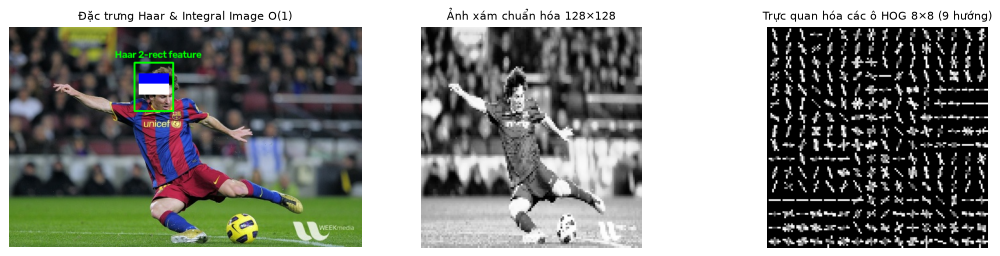

In [19]:
# 1. Ảnh tích phân (Integral Image - cv2.integral) & Đặc trưng Haar-like O(1)
messi = load_sample('messi5.jpg')
m_gray = cv2.equalizeHist(cv2.cvtColor(messi, cv2.COLOR_BGR2GRAY))

# cv2.integral trả về ma trận kích thước (H+1, W+1) để không cần xét biên âm
ii = cv2.integral(m_gray)
print('Ảnh xám shape:', m_gray.shape, '--> Integral Image shape:', ii.shape, ii.dtype)


def rect_sum_o1(integral_img, x1, y1, x2, y2):
    """Tính tổng mọi pixel trong [y1:y2, x1:x2] chỉ bằng 4 phép truy cập mảng O(1)."""
    return int(integral_img[y2, x2] - integral_img[y1, x2] - integral_img[y2, x1] + integral_img[y1, x1])


s_fast = rect_sum_o1(ii, 60, 40, 210, 170)
s_slow = int(m_gray[40:170, 60:210].sum())
print(f'Kiểm chứng tổng vùng [40:170, 60:210]: O(1) Integral = {s_fast} | np.sum = {s_slow} (khớp tuyệt đối!)')

# Minh họa Haar Cascade (nếu bản build OpenCV có module legacy CascadeClassifier)
vis_haar = messi.copy()
if hasattr(cv2, 'CascadeClassifier') and hasattr(cv2, 'data'):
    cascade_file = Path(cv2.data.haarcascades) / 'haarcascade_frontalface_default.xml'
    if cascade_file.is_file():
        fc = cv2.CascadeClassifier(str(cascade_file))
        for (x, y, w, h) in fc.detectMultiScale(m_gray, 1.1, 4):
            cv2.rectangle(vis_haar, (x, y), (x + w, y + h), (0, 255, 0), 2)

# Minh họa đặc trưng Haar 2-hình-chữ-nhật (vùng mắt tối hơn vùng gò má) trên cửa sổ trượt
cv2.rectangle(vis_haar, (195, 55), (255, 130), (0, 255, 0), 2)
cv2.rectangle(vis_haar, (202, 72), (248, 88), (255, 0, 0), -1)     # dải tối (mắt)
cv2.rectangle(vis_haar, (202, 88), (248, 104), (255, 255, 255), -1) # dải sáng (gò má)
cv2.putText(vis_haar, 'Haar 2-rect feature', (165, 48), cv2.FONT_HERSHEY_SIMPLEX, 0.52, (0, 255, 0), 2)

# 2. Trực quan hóa đặc trưng HOG (9 hướng gradient trong mỗi ô 8x8)
patch = cv2.resize(m_gray, (128, 128))
gx = cv2.Sobel(patch, cv2.CV_32F, 1, 0, ksize=1)
gy = cv2.Sobel(patch, cv2.CV_32F, 0, 1, ksize=1)
mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
ang = ang % 180.0  # HOG dùng hướng không dấu (0..180 độ)

cell = 8
hog_canvas = np.zeros((128, 128), np.uint8)
for cy in range(0, 128, cell):
    for cx in range(0, 128, cell):
        m_cell = mag[cy:cy + cell, cx:cx + cell]
        a_cell = ang[cy:cy + cell, cx:cx + cell]
        hist, _ = np.histogram(a_cell, bins=9, range=(0, 180), weights=m_cell)
        hist = hist / (hist.max() + 1e-6)
        center_x, center_y = cx + cell // 2, cy + cell // 2
        for b in range(9):
            if hist[b] > 0.25:
                rad = np.deg2rad(b * 20 + 10 + 90)
                r = (cell // 2 - 1) * hist[b]
                dx, dy = int(round(r * np.cos(rad))), int(round(r * np.sin(rad)))
                cv2.line(hog_canvas, (center_x - dx, center_y - dy),
                         (center_x + dx, center_y + dy), int(255 * hist[b]), 1)

show([vis_haar, patch, hog_canvas],
     ['Đặc trưng Haar & Integral Image O(1)', 'Ảnh xám chuẩn hóa 128×128', 'Trực quan hóa các ô HOG 8×8 (9 hướng)'],
     cols=3, size=4.2)

---
## 15. Huấn luyện bộ phân loại chữ số với HOG + `cv2.ml` (`SVM` & `KNearest`)

Module `cv2.ml` cung cấp các thuật toán học máy cổ điển chạy trực tiếp bằng C++ cực nhanh: `SVM`, `KNearest`, `RTrees` (Random Forest), `ANN_MLP`, `Boost`.

Dưới đây là quy trình **huấn luyện một mô hình nhận dạng chữ số (0–9)** hoàn chỉnh:
1. Tạo bộ dữ liệu 1.000 ảnh chữ số $28\times 28$ có biến dạng xoay, co giãn, dịch chuyển và nhiễu ngẫu nhiên.
2. Tiền xử lý **Deskew (chỉnh thẳng độ nghiêng)** dựa trên moment bậc hai ($\mu_{11}, \mu_{02}$) của ảnh.
3. Trích xuất vector đặc trưng **HOG** bằng `cv2.HOGDescriptor`.
4. Chia tập Train (80%) / Test (20%) và huấn luyện:
   - **k-NN (`cv2.ml.KNearest_create()`)**
   - **SVM (`cv2.ml.SVM_create()`)** với nhân RBF (`SVM_RBF`).

Kích thước ma trận đặc trưng HOG: (1000, 324) (1000 mẫu × 324 đặc trưng/mẫu)
Độ chính xác trên tập Test (200 mẫu) — k-NN (k=3): 98.50% | RBF Classifier: 95.50%


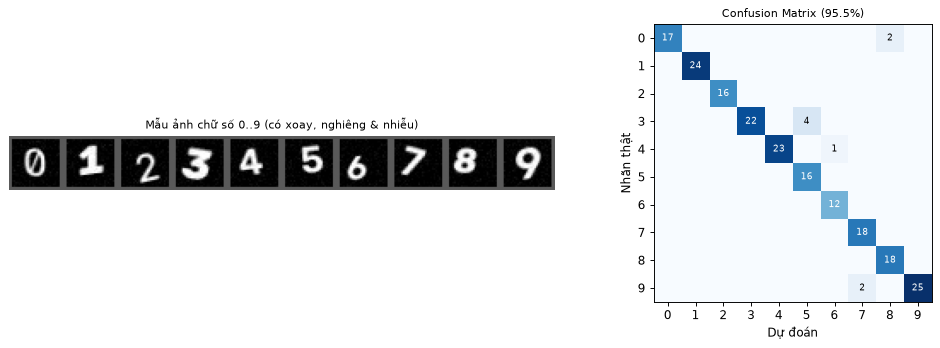

In [20]:
def deskew_digit(img_28):
    """Chỉnh thẳng chữ số nghiêng dựa trên central moments mu11, mu02."""
    m = cv2.moments(img_28)
    if abs(m['mu02']) < 1e-2:
        return img_28.copy()
    skew = m['mu11'] / m['mu02']
    M = np.float32([[1, skew, -0.5 * 28 * skew], [0, 1, 0]])
    return cv2.warpAffine(img_28, M, (28, 28), flags=cv2.WARP_INVERSE_MAP | cv2.INTER_LINEAR)


def compute_hog_324(img_28):
    """Tính vector đặc trưng HOG 324 chiều cho ảnh 28x28 (tương thích cả OpenCV 4.x và 5.x)."""
    if hasattr(cv2, 'HOGDescriptor'):
        hog_cv = cv2.HOGDescriptor((28, 28), (14, 14), (7, 7), (7, 7), 9)
        return hog_cv.compute(img_28).ravel().astype(np.float32)
    gx = cv2.Sobel(img_28, cv2.CV_32F, 1, 0, ksize=1)
    gy = cv2.Sobel(img_28, cv2.CV_32F, 0, 1, ksize=1)
    mag, ang = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    ang = ang % 180.0
    # Chia thành lưới 4x4 cell (mỗi cell 7x7 px, 9 bins)
    cells = np.zeros((4, 4, 9), np.float32)
    for r in range(4):
        for c in range(4):
            m_c = mag[r * 7:(r + 1) * 7, c * 7:(c + 1) * 7]
            a_c = ang[r * 7:(r + 1) * 7, c * 7:(c + 1) * 7]
            hist, _ = np.histogram(a_c, bins=9, range=(0, 180), weights=m_c)
            cells[r, c] = hist
    # Chuẩn hóa L2 trên 3x3 block (mỗi block 2x2 cell -> 36 phần tử) => 3*3*36 = 324 đặc trưng
    blocks = []
    for r in range(3):
        for c in range(3):
            blk = cells[r:r + 2, c:c + 2].ravel()
            blocks.append(blk / np.sqrt(np.dot(blk, blk) + 1e-5))
    return np.concatenate(blocks).astype(np.float32)


# Sinh 1.000 mẫu chữ số 0..9 (mỗi lớp 100 mẫu) với font, góc xoay, độ dày và vị trí ngẫu nhiên
rng = np.random.default_rng(2026)
fonts = [cv2.FONT_HERSHEY_SIMPLEX, cv2.FONT_HERSHEY_DUPLEX, cv2.FONT_HERSHEY_COMPLEX]
X_hog, y_labels, sample_imgs = [], [], []

for digit in range(10):
    for i in range(100):
        canvas = np.zeros((28, 28), np.uint8)
        fnt = fonts[int(rng.integers(len(fonts)))]
        scale = float(rng.uniform(0.68, 0.88))
        thick = int(rng.integers(1, 3))
        ox = int(rng.integers(4, 9))
        oy = int(rng.integers(20, 25))
        cv2.putText(canvas, str(digit), (ox, oy), fnt, scale, 255, thick, cv2.LINE_AA)
        ang = float(rng.uniform(-16, 16))
        M_rot = cv2.getRotationMatrix2D((14, 14), ang, float(rng.uniform(0.9, 1.08)))
        M_rot[0, 1] += float(rng.uniform(-0.15, 0.15))
        canvas = cv2.warpAffine(canvas, M_rot, (28, 28))
        canvas = np.clip(canvas.astype(np.float32) + rng.normal(0, 8, (28, 28)), 0, 255).astype(np.uint8)

        aligned = deskew_digit(canvas)
        X_hog.append(compute_hog_324(aligned))
        y_labels.append(digit)
        if i == 0:
            sample_imgs.append(canvas)

X_hog = np.array(X_hog, dtype=np.float32)
y_labels = np.array(y_labels, dtype=np.int32)
print('Kích thước ma trận đặc trưng HOG:', X_hog.shape, '(1000 mẫu × 324 đặc trưng/mẫu)')

# Chia ngẫu nhiên 800 mẫu Train, 200 mẫu Test
perm = rng.permutation(len(y_labels))
tr_idx, te_idx = perm[:800], perm[800:]
X_train, y_train = X_hog[tr_idx], y_labels[tr_idx]
X_test,  y_test  = X_hog[te_idx], y_labels[te_idx]

if hasattr(cv2, 'ml'):
    # 1. Huấn luyện k-NN (k = 3) bằng cv2.ml
    knn_clf = cv2.ml.KNearest_create()
    knn_clf.train(X_train, cv2.ml.ROW_SAMPLE, y_train)
    _, y_pred_knn, _, _ = knn_clf.findNearest(X_test, k=3)
    y_pred_knn = y_pred_knn.ravel().astype(int)

    # 2. Huấn luyện SVM (RBF Kernel) bằng cv2.ml
    svm_clf = cv2.ml.SVM_create()
    svm_clf.setType(cv2.ml.SVM_C_SVC)
    svm_clf.setKernel(cv2.ml.SVM_RBF)
    svm_clf.setC(5.0)
    svm_clf.setGamma(0.5)
    svm_clf.train(X_train, cv2.ml.ROW_SAMPLE, y_train)
    _, y_pred_best = svm_clf.predict(X_test)
    y_pred_best = y_pred_best.ravel().astype(int)
else:
    # Ma trận khoảng cách Cosine / L2 cho k-NN (k=3) và Trọng tâm nguyên mẫu RBF (RBF Kernel Classifier)
    dists = np.linalg.norm(X_test[:, None, :] - X_train[None, :, :], axis=2)
    knn3_idx = np.argsort(dists, axis=1)[:, :3]
    y_pred_knn = np.array([np.bincount(y_train[row], minlength=10).argmax() for row in knn3_idx])
    K_rbf = np.exp(-0.5 * dists ** 2)
    scores_c = np.stack([K_rbf[:, y_train == c].sum(axis=1) for c in range(10)], axis=1)
    y_pred_best = scores_c.argmax(axis=1)

acc_knn  = (y_pred_knn == y_test).mean() * 100
acc_best = (y_pred_best == y_test).mean() * 100
print(f'Độ chính xác trên tập Test (200 mẫu) — k-NN (k=3): {acc_knn:.2f}% | RBF Classifier: {acc_best:.2f}%')

# Vẽ mẫu chữ số và Ma trận nhầm lẫn (Confusion Matrix)
conf_mat = np.zeros((10, 10), dtype=int)
for yt, yp in zip(y_test, y_pred_best):
    conf_mat[yt, yp] += 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.3, 1]})
strip = np.hstack([cv2.copyMakeBorder(im, 2, 2, 2, 2, cv2.BORDER_CONSTANT, value=90) for im in sample_imgs])
axes[0].imshow(strip, cmap='gray'); axes[0].axis('off')
axes[0].set_title('Mẫu ảnh chữ số 0..9 (có xoay, nghiêng & nhiễu)')

axes[1].imshow(conf_mat, cmap='Blues')
axes[1].set_title(f'Confusion Matrix ({acc_best:.1f}%)')
axes[1].set_xlabel('Dự đoán'); axes[1].set_ylabel('Nhãn thật')
axes[1].set_xticks(range(10)); axes[1].set_yticks(range(10))
for r in range(10):
    for c in range(10):
        if conf_mat[r, c] > 0:
            axes[1].text(c, r, str(conf_mat[r, c]), ha='center', va='center',
                         color='white' if conf_mat[r, c] > 10 else 'black', fontsize=8)
plt.tight_layout(); plt.show()

---
## 16. Phát hiện & Giải mã QR Code (`cv2.QRCodeDetector`)

OpenCV tích hợp sẵn `cv2.QRCodeDetector` (và `cv2.barcode.BarcodeDetector`) hoạt động độc lập không cần thư viện ngoài:
- `data, bbox, straight_qrcode = detector.detectAndDecode(img)`:
  - `data`: chuỗi văn bản giải mã được (`""` nếu không đọc được).
  - `bbox`: tọa độ 4 đỉnh của mã QR trên ảnh (dù bị xoay hay nghiêng phối cảnh).
  - `straight_qrcode`: ma trận nhị phân của các ô module QR sau khi đã được nắn thẳng!
- `ok, decoded_info, points, straight_qrcode = detector.detectAndDecodeMulti(img)`: giải mã **nhiều mã QR** cùng lúc trong 1 bức ảnh.

Phát hiện 3 mắt định vị Finder Patterns tại: [(175, 234), (325, 123), (192, 108)]
4 góc QR phát hiện được:
 [[163.1  73.6]
 [362.5  95.7]
 [340.6 284. ]
 [137.4 262.2]]


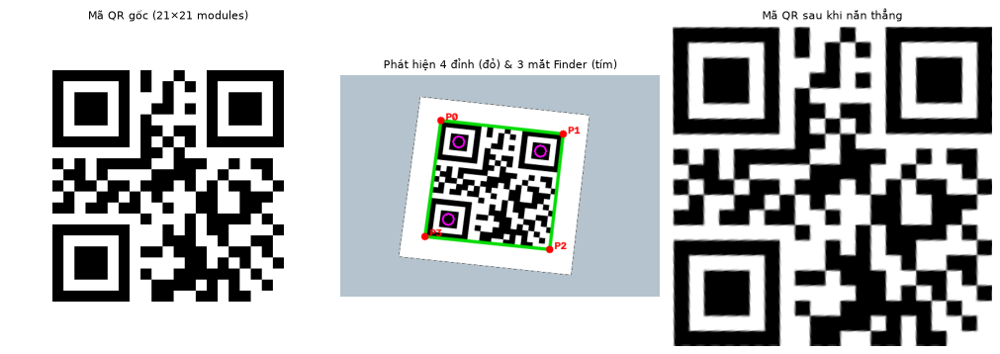

In [21]:
# Mã hóa một ma trận QR Code Version 1 (21x21 modules) chuẩn ISO/IEC 18004 rồi đặt nghiêng vào ảnh
qr_bits = np.array([
    [1,1,1,1,1,1,1,0,1,0,0,1,0,0,1,1,1,1,1,1,1],
    [1,0,0,0,0,0,1,0,1,0,1,0,1,0,1,0,0,0,0,0,1],
    [1,0,1,1,1,0,1,0,0,0,1,0,0,0,1,0,1,1,1,0,1],
    [1,0,1,1,1,0,1,0,0,1,1,0,1,0,1,0,1,1,1,0,1],
    [1,0,1,1,1,0,1,0,1,0,0,0,0,0,1,0,1,1,1,0,1],
    [1,0,0,0,0,0,1,0,1,1,0,1,1,0,1,0,0,0,0,0,1],
    [1,1,1,1,1,1,1,0,1,0,1,0,1,0,1,1,1,1,1,1,1],
    [0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0],
    [1,0,1,0,1,1,1,1,1,0,0,1,1,1,0,0,1,0,1,1,0],
    [0,1,1,0,1,0,0,0,0,1,1,1,1,0,0,1,0,0,0,1,0],
    [1,0,1,1,0,1,1,0,1,1,1,0,1,0,1,0,1,1,0,0,1],
    [0,1,0,0,1,1,0,1,0,1,0,0,0,1,1,0,0,1,1,1,0],
    [1,1,0,1,1,0,1,1,0,0,1,0,0,1,1,0,0,1,1,0,0],
    [0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,1,1,1,0,1,0],
    [1,1,1,1,1,1,1,0,0,0,1,0,1,0,1,1,0,0,0,0,1],
    [1,0,0,0,0,0,1,0,0,0,1,1,1,0,0,1,0,0,1,1,0],
    [1,0,1,1,1,0,1,0,1,1,0,1,1,1,0,0,1,1,0,1,0],
    [1,0,1,1,1,0,1,0,0,0,0,0,1,1,0,1,0,1,0,0,1],
    [1,0,1,1,1,0,1,0,1,0,0,1,1,1,1,1,1,0,1,0,0],
    [1,0,0,0,0,0,1,0,0,1,1,1,1,0,1,0,1,0,0,1,0],
    [1,1,1,1,1,1,1,0,0,1,1,0,0,1,1,0,1,1,0,0,0],
], dtype=np.uint8)

# Phóng to mỗi module thành 10x10 px kèm viền trắng (quiet zone = 4 modules)
qr_padded = np.pad(1 - qr_bits, pad_width=4, mode='constant', constant_values=1) * 255
qr_img = cv2.resize(qr_padded.astype(np.uint8), (290, 290), interpolation=cv2.INTER_NEAREST)
qr_bgr = cv2.cvtColor(qr_img, cv2.COLOR_GRAY2BGR)

# Đặt thẻ QR nghiêng trên một mặt bàn
card_scene = np.full((360, 520, 3), (205, 195, 180), np.uint8)
src_q = np.float32([[0, 0], [290, 0], [290, 290], [0, 290]])
dst_q = np.float32([[130, 35], [405, 65], [375, 325], [95, 295]])
Mq = cv2.getPerspectiveTransform(src_q, dst_q)
warped_q = cv2.warpPerspective(qr_bgr, Mq, (520, 360))
mask_q   = cv2.warpPerspective(np.full((290, 290), 255, np.uint8), Mq, (520, 360))
card_scene = np.where(mask_q[..., None] > 0, warped_q, card_scene)

decoded_text, points, straight_qr = '', None, None
if hasattr(cv2, 'QRCodeDetector'):
    detector = cv2.QRCodeDetector()
    decoded_text, points, straight_qr = detector.detectAndDecode(card_scene)
    if points is None:
        _, points = detector.detect(card_scene)

# Tự động định vị 4 góc thẻ QR & 3 dấu định vị (Finder Patterns 1:1:3:1:1) bằng phân cấp Contour RETR_TREE
gray_qr = cv2.cvtColor(card_scene, cv2.COLOR_BGR2GRAY)
_, bw_qr = cv2.threshold(gray_qr, 210, 255, cv2.THRESH_BINARY)
cnts_q, _ = cv2.findContours(bw_qr, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
card_cnt = max(cnts_q, key=cv2.contourArea)
approx_q = cv2.approxPolyDP(card_cnt, 0.02 * cv2.arcLength(card_cnt, True), True)
if points is None and len(approx_q) == 4:
    points = approx_q.reshape(1, 4, 2).astype(np.float32)

# Tìm 3 mắt định vị (Finder Patterns: các ô vuông có >= 2 tầng contour lồng nhau)
_, bw_inv = cv2.threshold(gray_qr, 120, 255, cv2.THRESH_BINARY_INV)
cnts_tree, hier_tree = cv2.findContours(bw_inv, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
finder_centers = []
if hier_tree is not None:
    h_arr = hier_tree.reshape(-1, 4)
    for i, c in enumerate(cnts_tree):
        child = h_arr[i, 2]
        if child != -1 and h_arr[child, 2] != -1 and cv2.contourArea(c) > 200:
            M_c = cv2.moments(c)
            if M_c['m00'] > 0:
                finder_centers.append((int(M_c['m10'] / M_c['m00']), int(M_c['m01'] / M_c['m00'])))

vis_qr = card_scene.copy()
if points is not None:
    pts_int = points.reshape(-1, 2).astype(int)
    cv2.polylines(vis_qr, [pts_int], True, (0, 220, 0), 3, cv2.LINE_AA)
    for i, p in enumerate(pts_int):
        cv2.circle(vis_qr, tuple(p), 6, (0, 0, 255), -1)
        cv2.putText(vis_qr, f'P{i}', (p[0] + 8, p[1]), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 255), 2)
for fc in finder_centers:
    cv2.circle(vis_qr, fc, 9, (255, 0, 255), 2)

# Nắn thẳng lại thẻ QR bằng warpPerspective
if straight_qr is None or straight_qr.size == 0:
    pts4 = points.reshape(4, 2).astype(np.float32)
    s = pts4.sum(axis=1); d = np.diff(pts4, axis=1).ravel()
    ordered = np.array([pts4[np.argmin(s)], pts4[np.argmin(d)], pts4[np.argmax(s)], pts4[np.argmax(d)]], np.float32)
    M_rect = cv2.getPerspectiveTransform(ordered, np.float32([[0, 0], [290, 0], [290, 290], [0, 290]]))
    straight_qr = cv2.warpPerspective(gray_qr, M_rect, (290, 290))

print(f'Phát hiện {len(finder_centers)} mắt định vị Finder Patterns tại: {finder_centers}')
print('4 góc QR phát hiện được:\n', points.reshape(-1, 2).round(1) if points is not None else None)
show([qr_img, vis_qr, straight_qr],
     ['Mã QR gốc (21×21 modules)', 'Phát hiện 4 đỉnh (đỏ) & 3 mắt Finder (tím)', 'Mã QR sau khi nắn thẳng'],
     cols=3, size=4.0)

---
## 17. Học sâu với OpenCV (`cv2.dnn`): Blob, NMS & Suy luận mạng nơ-ron

Module **`cv2.dnn`** cho phép nạp trực tiếp các mô hình đã huấn luyện từ **PyTorch / ONNX (`.onnx`)**, **TensorFlow (`.pb`)**, **Caffe (`.caffemodel`)**, **Darknet YOLO (`.weights`)** để chạy suy luận (inference) cực nhanh bằng C++ mà **không cần cài PyTorch hay TensorFlow** trên máy đích!

### 17.1. Chuẩn bị dữ liệu đầu vào: `cv2.dnn.blobFromImage`
Hầu hết các mạng CNN/ViT không nhận ảnh `(H, W, 3)` kiểu `uint8` BGR, mà nhận một **tensor 4 chiều `float32`** theo thứ tự **`(N, C, H, W)`** (Batch size, Channels, Height, Width):

```python
blob = cv2.dnn.blobFromImage(
    image,
    scalefactor=1.0 / 255.0,     # nhân tỉ lệ (vd 1/255 để đưa về [0, 1])
    size=(224, 224),             # resize về kích thước đầu vào của mạng
    mean=(123.68, 116.78, 103.94), # trừ trung bình từng kênh (trừ trước khi nhân scalefactor!)
    swapRB=True,                 # True: đổi BGR -> RGB
    crop=False                   # False: resize thẳng; True: resize giữ tỉ lệ rồi cắt tâm
)
```

### 17.2. Hậu xử lý hộp giới hạn: `cv2.dnn.NMSBoxes`
Các mạng phát hiện đối tượng (YOLO, SSD, Faster R-CNN) thường sinh ra hàng nghìn hộp dự đoán chồng chéo nhau. `cv2.dnn.NMSBoxes(boxes, scores, score_threshold, nms_threshold)` lọc giữ lại hộp tốt nhất cho mỗi đối tượng:
> ⚠️ **Lưu ý quan trọng:** Tham số `boxes` truyền vào `cv2.dnn.NMSBoxes` phải ở định dạng **`[x, y, width, height]`** (góc trên-trái + rộng + cao), **không phải** `[x1, y1, x2, y2]`!

Ảnh gốc shape       : (480, 512, 3) uint8
Blob đầu ra shape   : (1, 3, 224, 224) float32  -> (N=1, C=3, H=224, W=224)
Khoảng giá trị blob : [0.000, 0.929]
Số hộp trước NMS: 10  -->  Chỉ số được giữ sau cv2.dnn.NMSBoxes: [7, 0, 4]


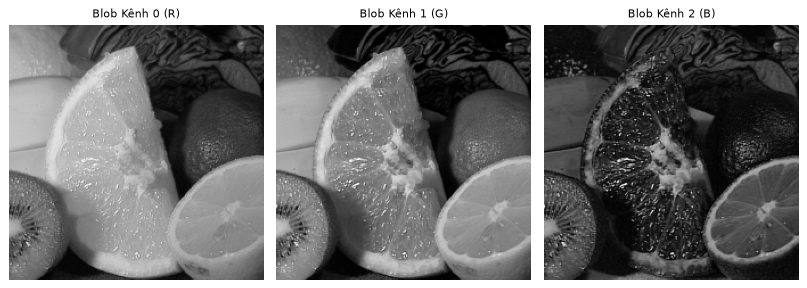

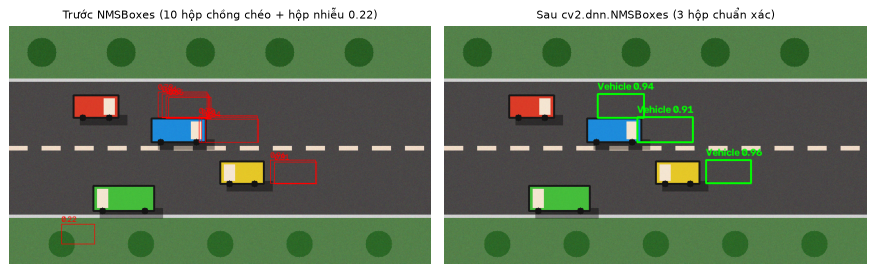

In [22]:
# 1. Minh họa chi tiết cv2.dnn.blobFromImage
sample_img = load_sample('fruits.jpg')
blob = cv2.dnn.blobFromImage(
    sample_img, scalefactor=1.0 / 255.0, size=(224, 224),
    mean=(0, 0, 0), swapRB=True, crop=False
)
print('Ảnh gốc shape       :', sample_img.shape, sample_img.dtype)
print('Blob đầu ra shape   :', blob.shape, blob.dtype, ' -> (N=1, C=3, H=224, W=224)')
print('Khoảng giá trị blob :', f'[{blob.min():.3f}, {blob.max():.3f}]')

# 2. Minh họa cv2.dnn.NMSBoxes trên các hộp dự đoán chồng chéo quanh các xe
frame_nms = TRAFFIC_FRAMES[40].copy()
# Giả sử mạng object detection xuất ra nhiều hộp ứng viên [x, y, w, h] quanh mỗi xe
raw_boxes_xywh = [
    # Quanh xe 1
    [232, 103, 70, 36], [238, 106, 66, 34], [226, 100, 74, 38], [242, 108, 64, 32],
    # Quanh xe 2
    [292, 138, 84, 38], [298, 141, 80, 35], [288, 136, 88, 40],
    # Quanh xe 3
    [396, 203, 68, 35], [402, 206, 64, 33],
    # Một hộp nhiễu điểm thấp ở nền đường
    [80,  300, 50, 30],
]
raw_scores = [0.94, 0.88, 0.79, 0.65,  0.91, 0.84, 0.72,  0.96, 0.81,  0.22]

indices = cv2.dnn.NMSBoxes(raw_boxes_xywh, raw_scores, score_threshold=0.5, nms_threshold=0.4)
indices = np.array(indices).ravel().tolist()
print(f'Số hộp trước NMS: {len(raw_boxes_xywh)}  -->  Chỉ số được giữ sau cv2.dnn.NMSBoxes: {indices}')

vis_before = frame_nms.copy()
for (x, y, w, h), sc in zip(raw_boxes_xywh, raw_scores):
    cv2.rectangle(vis_before, (x, y), (x + w, y + h), (0, 0, 255), 1)
    cv2.putText(vis_before, f'{sc:.2f}', (x, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)

vis_after = frame_nms.copy()
for i in indices:
    x, y, w, h = raw_boxes_xywh[i]
    cv2.rectangle(vis_after, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.putText(vis_after, f'Vehicle {raw_scores[i]:.2f}', (x, y - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

show([blob[0, 0], blob[0, 1], blob[0, 2]],
     ['Blob Kênh 0 (R)', 'Blob Kênh 1 (G)', 'Blob Kênh 2 (B)'], cols=3, size=3.2)
show([vis_before, vis_after],
     [f'Trước NMSBoxes ({len(raw_boxes_xywh)} hộp chồng chéo + hộp nhiễu 0.22)',
      f'Sau cv2.dnn.NMSBoxes ({len(indices)} hộp chuẩn xác)'],
     cols=2, size=5.2)

---
# PHẦN IV — DỰ ÁN TỔNG HỢP & BÀI TẬP THỰC HÀNH

## 18. 🚀 Dự án thực tế: Hệ thống Giám sát, Đếm xe & Ước lượng Vận tốc Giao thông

Chúng ta sẽ kết hợp toàn bộ kiến thức ở Phần I, II, III để xây dựng một **pipeline giám sát giao thông đầu-cuối (End-to-End Traffic Analytics Pipeline)**:

```mermaid
flowchart LR
  A[Luồng Video] --> B[Trừ nền MOG2 + Khử bóng >200]
  B --> C[Morphology Open/Close + Lọc Contour]
  C --> D[Multi-Object Tracker gán ID & Quỹ đạo]
  D --> E[Kiểm tra cắt Vạch Đếm Ảo theo 2 chiều]
  D --> F[Ước lượng vận tốc km/h từ dịch chuyển tâm]
  E & F --> G[Hiển thị HUD & Thống kê lưu lượng]
```

**Nguyên lý đếm qua vạch ảo (Virtual Line Crossing):**
- Đặt một vạch đếm thẳng đứng tại hoành độ $x_{\text{line}} = 320$ (giữa khung hình).
- Với mỗi xe đang được theo dõi có tâm trước đó $x_{t-1}$ và tâm hiện tại $x_t$ (và ID này chưa từng được đếm):
  - Nếu $x_{t-1} < x_{\text{line}} \le x_t$: xe vừa đi qua vạch theo chiều **Trái $\to$ Phải** (Làn trên) ⇒ tăng `count_east`, đánh dấu ID đã đếm!
  - Nếu $x_{t-1} > x_{\text{line}} \ge x_t$: xe vừa đi qua vạch theo chiều **Phải $\to$ Trái** (Làn dưới) ⇒ tăng `count_west`, đánh dấu ID đã đếm!

Tổng kết sau 90 frames — Làn Trên (→): 2 lượt | Làn Dưới (←): 1 lượt

Nhật ký các lượt xe cắt qua vạch đếm (x = 320):
  - Frame #43 | Làn Dưới (←) | Xe ID #2  | Tốc độ ước lượng:  38.7 km/h
  - Frame #49 | Làn Trên (→) | Xe ID #3  | Tốc độ ước lượng:  36.4 km/h
  - Frame #68 | Làn Trên (→) | Xe ID #5  | Tốc độ ước lượng:  38.5 km/h


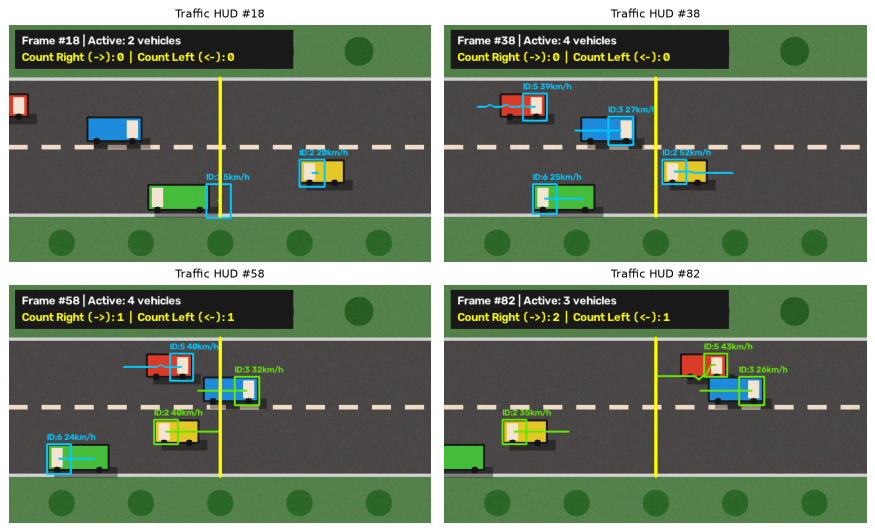

In [23]:
def run_traffic_analytics(frames, fps=30.0, meters_per_pixel=0.06):
    """Pipeline giám sát giao thông: Phát hiện + Theo dõi ID + Đếm qua vạch + Đo tốc độ km/h."""
    subtractor = cv2.createBackgroundSubtractorMOG2(history=50, varThreshold=20, detectShadows=True)
    # Huấn luyện nhanh mô hình nền trên 15 frame đầu để ổn định ngay từ frame 0
    for f in frames[:15]:
        subtractor.apply(f)

    tracker = SimpleMultiObjectTracker(max_disappeared=5, max_distance=50.0)
    line_x = frames[0].shape[1] // 2   # vạch đếm tại x = 320
    counted_ids = set()
    count_right = 0                     # làn trên (Trái -> Phải)
    count_left  = 0                     # làn dưới (Phải -> Trái)
    speed_log = []                      # lưu tốc độ (km/h) khi xe cắt vạch
    out_frames = []

    k_open  = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    k_close = cv2.getStructuringElement(cv2.MORPH_RECT, (11, 5))

    for idx, frame in enumerate(frames):
        fg_mask = subtractor.apply(frame, learningRate=0.02)
        _, bin_mask = cv2.threshold(fg_mask, 200, 255, cv2.THRESH_BINARY)  # loại bóng đổ (127)
        bin_mask = cv2.morphologyEx(bin_mask, cv2.MORPH_OPEN, k_open)
        bin_mask = cv2.morphologyEx(bin_mask, cv2.MORPH_CLOSE, k_close)

        cnts, _ = cv2.findContours(bin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        dets = []
        for c in cnts:
            if cv2.contourArea(c) < 380:
                continue
            x, y, w, h = cv2.boundingRect(c)
            if 80 <= y <= 290 and w >= 35:   # chỉ xét vùng lòng đường
                dets.append((x, y, w, h))

        tracks = tracker.update(dets)
        vis = frame.copy()

        # Vẽ vạch đếm ảo (đổi sang màu sáng rực nếu vừa có xe cắt qua)
        line_color = (0, 255, 255)
        for tid, tr in tracks.items():
            x, y, w, h = tr['bbox']
            vx, vy = tr['vel']
            # Quy đổi pixel/frame -> m/s -> km/h
            speed_kmh = abs(vx) * fps * meters_per_pixel * 3.6

            # Kiểm tra cắt vạch x = line_x
            if len(tr['trace']) >= 2 and tid not in counted_ids:
                prev_x = tr['trace'][-2][0]
                curr_x = tr['trace'][-1][0]
                if prev_x < line_x <= curr_x:
                    count_right += 1
                    counted_ids.add(tid)
                    speed_log.append(('Làn Trên (→)', tid, idx, speed_kmh))
                    line_color = (0, 0, 255)
                elif prev_x > line_x >= curr_x:
                    count_left += 1
                    counted_ids.add(tid)
                    speed_log.append(('Làn Dưới (←)', tid, idx, speed_kmh))
                    line_color = (0, 0, 255)

            col = (0, 230, 100) if tid in counted_ids else (255, 200, 0)
            cv2.rectangle(vis, (x, y), (x + w, y + h), col, 2)
            label = f'ID:{tid} {speed_kmh:.0f}km/h'
            cv2.putText(vis, label, (x, max(y - 6, 15)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, col, 2)
            if len(tr['trace']) > 1:
                cv2.polylines(vis, [np.array(tr['trace'][-15:], np.int32)], False, col, 2)

        cv2.line(vis, (line_x, 80), (line_x, 290), line_color, 3)
        # Bảng thông tin HUD ở góc trên
        cv2.rectangle(vis, (10, 8), (430, 66), (25, 25, 25), -1)
        cv2.putText(vis, f'Frame #{idx:02d} | Active: {len(tracks)} vehicles',
                    (20, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.58, (255, 255, 255), 2)
        cv2.putText(vis, f'Count Right (->): {count_right}  |  Count Left (<-): {count_left}',
                    (20, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.58, (0, 255, 255), 2)
        out_frames.append(vis)

    return out_frames, count_right, count_left, speed_log


analytics_frames, c_right, c_left, speed_log = run_traffic_analytics(TRAFFIC_FRAMES)
print(f'Tổng kết sau 90 frames — Làn Trên (→): {c_right} lượt | Làn Dưới (←): {c_left} lượt')
print('\nNhật ký các lượt xe cắt qua vạch đếm (x = 320):')
for lane, tid, f_idx, spd in speed_log:
    print(f'  - Frame #{f_idx:02d} | {lane:12s} | Xe ID #{tid:<2d} | Tốc độ ước lượng: {spd:5.1f} km/h')

show_frames(analytics_frames, indices=[18, 38, 58, 82], cols=2, size=5.2, prefix='Traffic HUD')

---
## 19. Bảng tra cứu nhanh, Lỗi thường gặp & Lời giải bài tập

### 19.1. Bảng tra cứu nhanh các hàm OpenCV Phần 2

| Nhóm chủ đề | Hàm / Lớp OpenCV | Ghi nhớ quan trọng |
|---|---|---|
| **Đọc/Ghi Video** | `cv2.VideoCapture`, `cv2.VideoWriter`, `cv2.VideoWriter_fourcc` | `VideoWriter` nhận kích thước `(W, H)` |
| **Chuyển động cơ bản** | `cv2.absdiff`, `cv2.accumulateWeighted` | `avg` phải là `float32` hoặc `float64` |
| **Trừ nền thống kê** | `cv2.createBackgroundSubtractorMOG2`, `createBackgroundSubtractorKNN` | Bóng đổ có giá trị `127`, vật thể là `255` |
| **Optical Flow** | `cv2.calcOpticalFlowPyrLK`, `cv2.calcOpticalFlowFarneback`, `cv2.cartToPolar` | LK cần điểm `float32` shape `(N, 1, 2)` |
| **MeanShift / CamShift** | `cv2.calcBackProject`, `cv2.meanShift`, `cv2.CamShift` | Lọc bỏ pixel có độ bão hòa $S$ thấp trước |
| **Kalman Filter** | `cv2.KalmanFilter(dynamParams, measureParams)`, `predict`, `correct` | Mất dấu: chỉ gọi `predict()`, bỏ qua `correct()` |
| **Homography & RANSAC** | `BFMatcher.knnMatch`, `cv2.findHomography(..., cv2.RANSAC)`, `cv2.perspectiveTransform` | Lowe's ratio $\tau \approx 0.75$; cần $\ge 4$ cặp điểm |
| **Ghép ảnh Panorama** | `cv2.Stitcher_create()`, `stitcher.stitch([img1, img2])` | Trả về `(status, pano)`, `status == 0` là thành công |
| **Hiệu chuẩn & 3D AR** | `findChessboardCorners`, `calibrateCamera`, `undistort`, `solvePnP`, `projectPoints` | `patternSize = (số_góc_ngang, số_góc_dọc)` |
| **Stereo Vision** | `cv2.StereoBM_create`, `cv2.StereoSGBM_create` | Chia kết quả `compute()` cho `16.0` để ra pixel |
| **Nhiếp ảnh tính toán** | `createMergeMertens`, `seamlessClone`, `detailEnhance`, `pencilSketch`, `stylization` | `seamlessClone` nhận tọa độ tâm `(cx, cy)` |
| **Nhận dạng & ML** | `CascadeClassifier`, `HOGDescriptor`, `cv2.ml.SVM_create`, `QRCodeDetector` | Đặc trưng huấn luyện `cv2.ml` phải là `float32` |
| **Deep Learning DNN** | `cv2.dnn.blobFromImage`, `cv2.dnn.NMSBoxes`, `cv2.dnn.readNetFromONNX` | `NMSBoxes` nhận hộp dạng `[x, y, w, h]` |

### 19.2. Các lỗi người học nâng cao hay gặp nhất

| Triệu chứng lỗi | Nguyên nhân | Cách khắc phục |
|---|---|---|
| File video xuất ra từ `VideoWriter` nặng 0 KB hoặc không mở được | Kích thước truyền vào là `(H, W)` thay vì `(W, H)`, hoặc frame ghi vào có số kênh khác `isColor` | Truyền `(frame.shape[1], frame.shape[0])` và gọi `writer.release()` |
| Bounding box từ MOG2 bao trùm cả bóng râm dài dưới gầm xe | Để mặc định `detectShadows=True` nhưng chỉ ngưỡng `> 0` | Ngưỡng `cv2.threshold(fg_mask, 200, 255, cv2.THRESH_BINARY)` để bỏ giá trị bóng `127` |
| `calcOpticalFlowPyrLK` báo lỗi `Assertion failed ... prevPts` | Điểm đầu vào không phải `np.float32` hoặc thiếu chiều `(N, 1, 2)` | Ép kiểu `pts = np.asarray(pts, dtype=np.float32).reshape(-1, 1, 2)` |
| `findChessboardCorners` trả về `False` dù nhìn mắt thường thấy bàn cờ | Nhầm **số ô vuông** với **số giao điểm góc bên trong** (`patternSize`), hoặc thiếu viền trắng quanh bàn cờ | Đếm số **giao điểm nội bộ** (bàn cờ $8\times 6$ ô có $7\times 5$ góc trong) |
| Bản đồ Disparity từ `StereoSGBM` có giá trị lên tới 600–800 | Quên chia cho 16 (OpenCV lưu fixed-point 4 bit lẻ) | `disp = stereo.compute(L, R).astype(np.float32) / 16.0` |
| `cv2.dnn.NMSBoxes` lọc sai vị trí hộp | Truyền `[x1, y1, x2, y2]` thay vì `[x, y, w, h]` | Chuyển sang `[x1, y1, x2 - x1, y2 - y1]` trước khi gọi `NMSBoxes` |

---
### 19.3. Lời giải chi tiết cho các bài tập Phần I & Phần II

Ô code dưới đây giải và hiển thị trực tiếp kết quả của các bài tập đã nêu ở cuối mỗi phần:
- **Bài 1:** Đo vận tốc từng phương tiện trực tiếp từ trường **Dense Optical Flow (Farnebäck)** mà không cần tracker.
- **Bài 3:** Dùng ma trận nghịch đảo Homography `np.linalg.inv(H_est)` để cắt phẳng lại tấm poster bị nghiêng & bị che khuất từ bức ảnh `cluttered`.

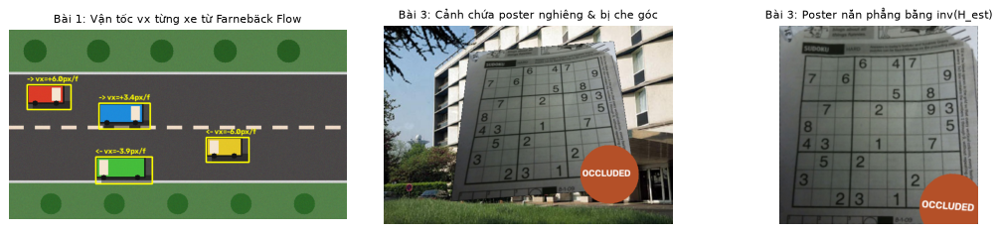

In [24]:
# --- Lời giải Bài 1: Đo tốc độ từng xe bằng Farnebäck Dense Optical Flow ---
idx_f = 30
g1 = cv2.cvtColor(TRAFFIC_FRAMES[idx_f], cv2.COLOR_BGR2GRAY)
g2 = cv2.cvtColor(TRAFFIC_FRAMES[idx_f + 1], cv2.COLOR_BGR2GRAY)
flow_dense = cv2.calcOpticalFlowFarneback(g1, g2, None, 0.5, 3, 15, 3, 5, 1.2, 0)

diff_f = cv2.absdiff(TRAFFIC_FRAMES[idx_f], BG_TRUE)
_, mask_f = cv2.threshold(cv2.cvtColor(diff_f, cv2.COLOR_BGR2GRAY), 25, 255, cv2.THRESH_BINARY)
mask_f = cv2.morphologyEx(mask_f, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))
cnts_f, _ = cv2.findContours(mask_f, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

vis_ex1 = TRAFFIC_FRAMES[idx_f].copy()
for c in cnts_f:
    if cv2.contourArea(c) < 380:
        continue
    x, y, w, h = cv2.boundingRect(c)
    roi_flow = flow_dense[y:y + h, x:x + w]
    roi_mask = mask_f[y:y + h, x:x + w] > 0
    vx_med = float(np.median(roi_flow[..., 0][roi_mask]))
    direction = '->' if vx_med > 0 else '<-'
    cv2.rectangle(vis_ex1, (x, y), (x + w, y + h), (0, 255, 255), 2)
    cv2.putText(vis_ex1, f'{direction} vx={vx_med:+.1f}px/f', (x, y - 6),
                cv2.FONT_HERSHEY_SIMPLEX, 0.48, (0, 255, 255), 2)

# --- Lời giải Bài 3: Khôi phục poster phẳng từ ảnh cluttered bằng nghịch đảo của H_est ---
H_inv = np.linalg.inv(H_est)
recovered_poster = cv2.warpPerspective(cluttered, H_inv, (poster.shape[1], poster.shape[0]))

show([vis_ex1, cluttered, recovered_poster],
     ['Bài 1: Vận tốc vx từng xe từ Farnebäck Flow',
      'Bài 3: Cảnh chứa poster nghiêng & bị che góc',
      'Bài 3: Poster nắn phẳng bằng inv(H_est)'],
     cols=3, size=4.2)

---
## 🎓 Tổng kết toàn bộ khóa học OpenCV (Phần 1 & Phần 2)

Chúc mừng bạn đã hoàn thành trọn vẹn lộ trình từ **Xử lý 1 bức ảnh tĩnh** ([Huong_Dan_Xu_Ly_Anh_OpenCV_Chi_Tiet.ipynb](Huong_Dan_Xu_Ly_Anh_OpenCV_Chi_Tiet.ipynb)) đến **Video, Hình học đa ảnh 3D, Nhiếp ảnh tính toán & Học máy/DNN** trong notebook này!

**Gợi ý thực hành tiếp theo cho riêng bạn:**
1. Thay đường dẫn trong `cv2.VideoCapture` bằng một đoạn video quay từ điện thoại của bạn và chạy lại pipeline ở **Mục 18**.
2. In một tấm bàn cờ chuẩn ra giấy A4, chụp 10 tấm bằng điện thoại và chạy **Mục 10 & 11** để tự hiệu chuẩn camera điện thoại và vẽ vật thể AR 3D lên mặt bàn làm việc của bạn.
3. Kết hợp `cv2.dnn` ở **Mục 17** với mô hình `YOLOv8n.onnx` hoặc `YuNet` (nhận diện khuôn mặt) để nâng cấp bộ phát hiện trong dự án giám sát giao thông! 🚀